In [1]:
!pip install infercnvpy


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


In [2]:
import os
import warnings
import warnings ; warnings.warn = lambda *args,**kwargs: None
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np
import glob
from pathlib import Path
import infercnvpy as cnv
import traceback


In [3]:
adata_core = sc.read_h5ad('/workspace/PDAC_Work_Dir/PDAC_Final/Human_Atlas_Harmonised_genes_filtered_Core.h5ad')

In [4]:
adata_core.obs.Level_3.unique()

['Dendritic Cell', 'Malignant Cell - Mesenchymal', 'CD4+ T Cell', 'CD8+ T Cell', 'Macrophage', ..., 'Acinar Idling Cell', 'Alpha Cell', 'Acinar Cell', 'Pericyte', 'Smooth Muscle Cell']
Length: 28
Categories (28, object): ['CD4+ T Cell' < 'CD8+ T Cell' < 'Mixed T Cell' < 'NK Cell' ... 'Other Endocrine' < 'Malignant Cell - Epithelial' < 'Malignant Cell - EMT' < 'Malignant Cell - Mesenchymal']

In [5]:
!pip install genomic_features

  Using cached genomic_features-0.0.1a0-py3-none-any.whl.metadata (4.8 kB)
  Using cached ibis_framework-12.0.0-py3-none-any.whl.metadata (21 kB)
  Using cached pooch-1.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached pyarrow-24.0.0-cp312-cp312-manylinux_2_28_x86_64.whl.metadata (3.0 kB)
  Using cached atpublic-7.0.0-py3-none-any.whl.metadata (2.0 kB)
  Using cached parsy-2.2-py3-none-any.whl.metadata (3.7 kB)
  Using cached sqlglot-30.12.0-py3-none-any.whl.metadata (24 kB)
  Using cached toolz-1.1.0-py3-none-any.whl.metadata (5.1 kB)
  Using cached pyarrow_hotfix-0.7-py3-none-any.whl.metadata (3.6 kB)
  Using cached regex-2026.6.28-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (40 kB)
Using cached genomic_features-0.0.1a0-py3-none-any.whl (7.6 kB)
Using cached ibis_framework-12.0.0-py3-none-any.whl (2.1 MB)
Using cached atpublic-7.0.0-py3-none-any.whl (6.4 kB)
Using cached parsy-2.2-py3-none-any.whl (9.5 kB)
Using cached pyarrow-24.0.0-c

In [6]:
import genomic_features as gf

ensdb = gf.ensembl.annotation(species="Hsapiens", version="108")
genes = ensdb.db.table("gene").execute()
dict_map = {gene: (start, end, chrom) for gene, start, end, chrom in zip(genes.gene_name, genes.gene_seq_start, genes.gene_seq_end, genes.seq_name)}

In [7]:
adata_core.obs.Level_3.value_counts().sort_index()

Level_3
CD4+ T Cell                      42378
CD8+ T Cell                      87391
Mixed T Cell                      3228
NK Cell                          10647
B Cell                           26274
Plasma Cell                       5070
Dendritic Cell                    6350
Monocyte                         20202
Macrophage                       41348
Neutrophil                       20136
Mast Cell                        13002
Cancer Associated Fibroblast     80972
Pericyte                         11563
Smooth Muscle Cell                4303
Schwann Cell                      4666
Endothelial Cell                 41104
Adipocyte                         1459
Ductal Cell                      20799
Ductal Cell (atypical)           38369
Acinar Cell                       4342
Acinar Idling Cell                7407
Acinar (REG+) Cell               11545
Alpha Cell                        4730
Beta Cell                         7035
Other Endocrine                   6456
Malignant Cell - 

In [8]:
adata_core.obs['Dataset_Tech'] = adata_core.obs['Dataset'].astype(str) + '_' + adata_core.obs['Technology'].astype(str)

In [9]:
adata_core.obs['Dataset_Tech'].value_counts().sort_index()

Dataset_Tech
Caronni_2023_scRNA-seq         71985
Ding_2022_scRNA-seq           146983
Ding_2022_snRNA-seq            58888
Hwang_2022_snRNA-seq          186330
Kemp_2020_scRNA-seq             2714
Lee_2021_scRNA-seq              8136
Lin_2020_scRNA-seq              8019
Peng_2019_scRNA-seq            56079
Schlesinger_2020_scRNA-seq      5387
Simeone_2023_scRNA-seq        141988
Steele_2020_scRNA-seq          42259
Yue_2020_scRNA-seq             76094
Name: count, dtype: int64

In [10]:
os.chdir('/workspace/PDAC_Work_Dir/PDAC_Final/PDAC_Revisions')

In [11]:
sc.set_figure_params(dpi=100, dpi_save=300)

In [12]:
for dataset in adata_core.obs.Dataset_Tech.unique():
    print(adata_core[adata_core.obs.Dataset_Tech == dataset].X.max())

8003.0
10764.0
30420.0
151380.0
38145.0
18642.0
16332.0
5315.0
2294.0
3891.0
26655.0
12059.0


Processing dataset Ding_2022_scRNA-seq
Inferring CNVs for Ding_2022_scRNA-seq


100%|██████████| 30/30 [00:30<00:00,  1.01s/it]


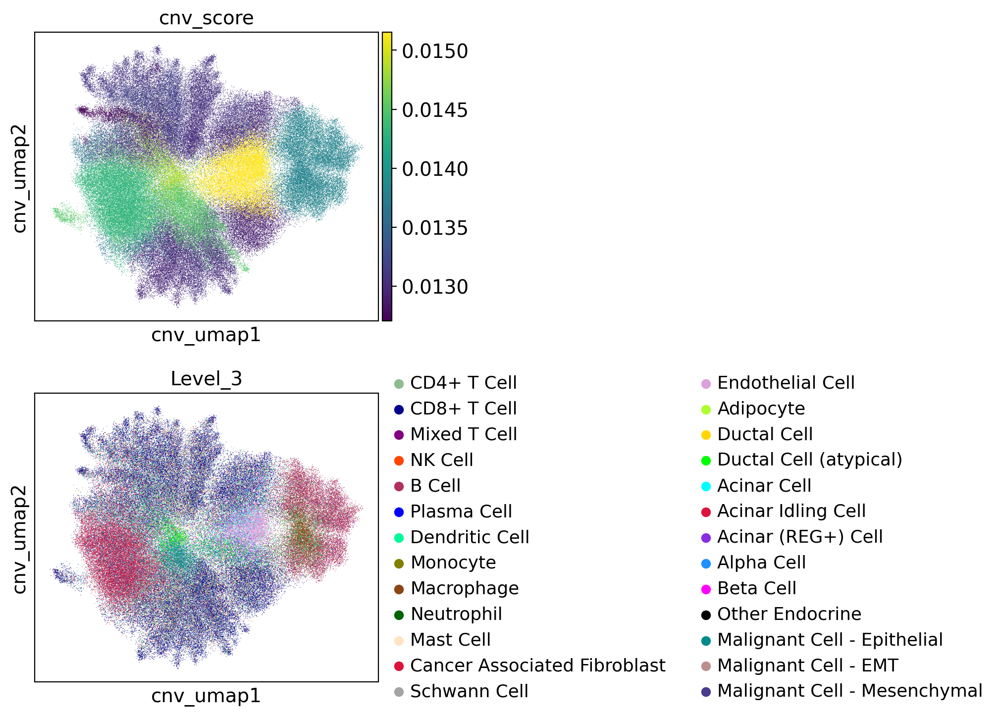

Finished processing dataset Ding_2022_scRNA-seq
Processing dataset Lee_2021_scRNA-seq
Inferring CNVs for Lee_2021_scRNA-seq


100%|██████████| 2/2 [00:06<00:00,  3.41s/it]


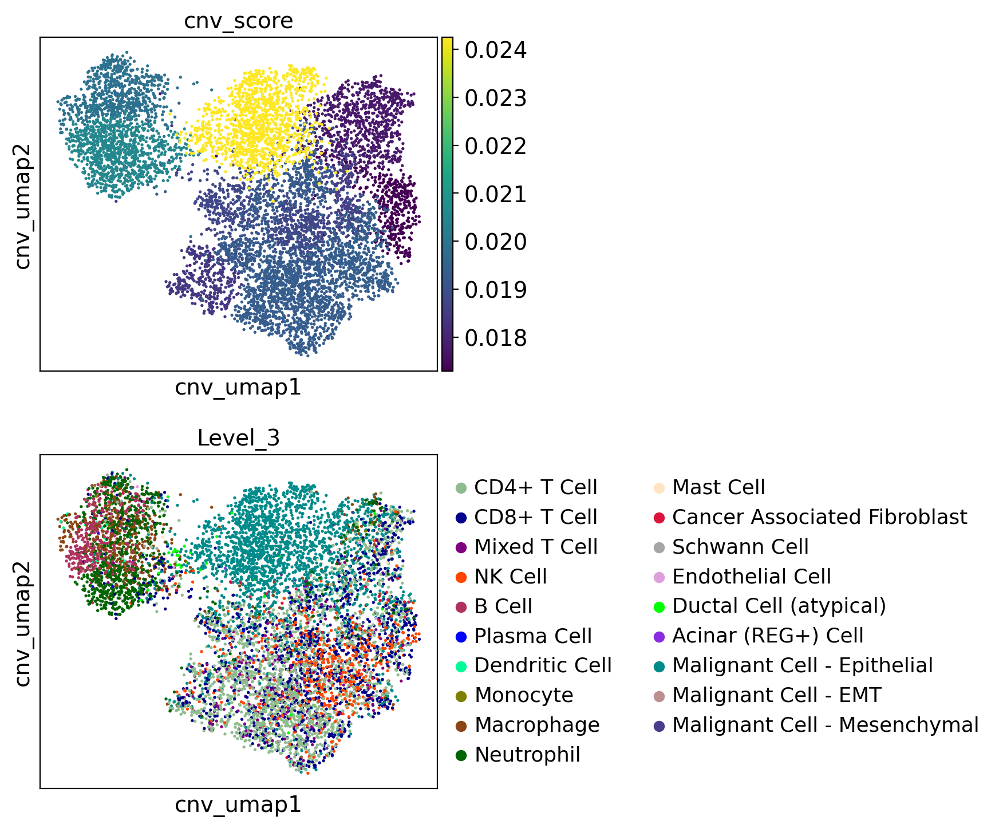

Finished processing dataset Lee_2021_scRNA-seq
Processing dataset Simeone_2023_scRNA-seq
Inferring CNVs for Simeone_2023_scRNA-seq


100%|██████████| 29/29 [00:29<00:00,  1.02s/it]


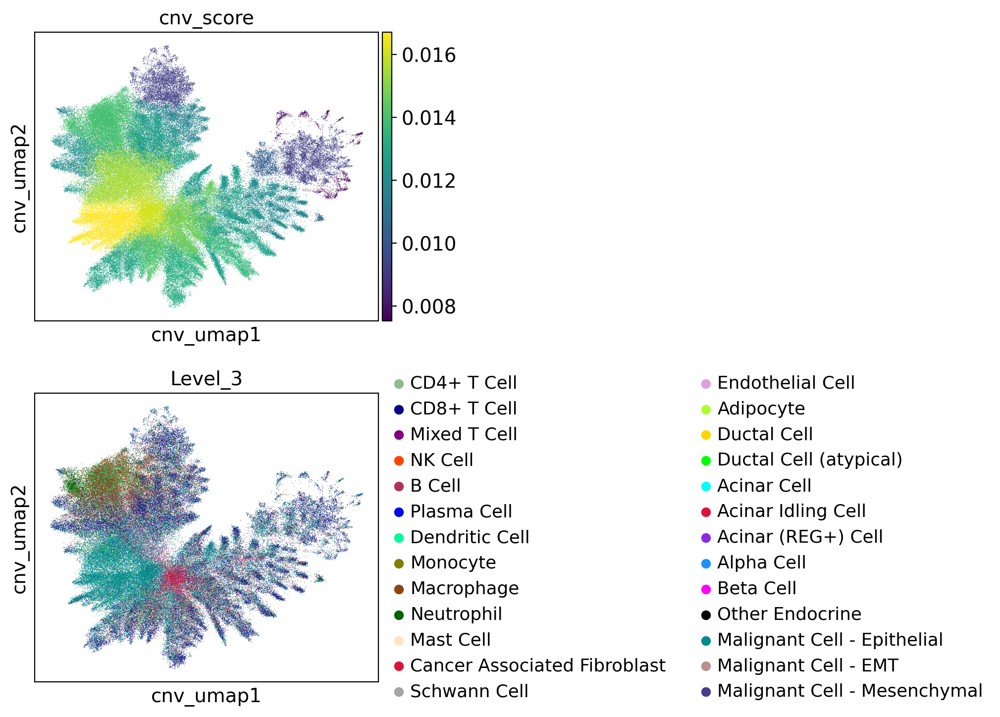

Finished processing dataset Simeone_2023_scRNA-seq
Processing dataset Steele_2020_scRNA-seq
Inferring CNVs for Steele_2020_scRNA-seq


100%|██████████| 9/9 [00:11<00:00,  1.28s/it]


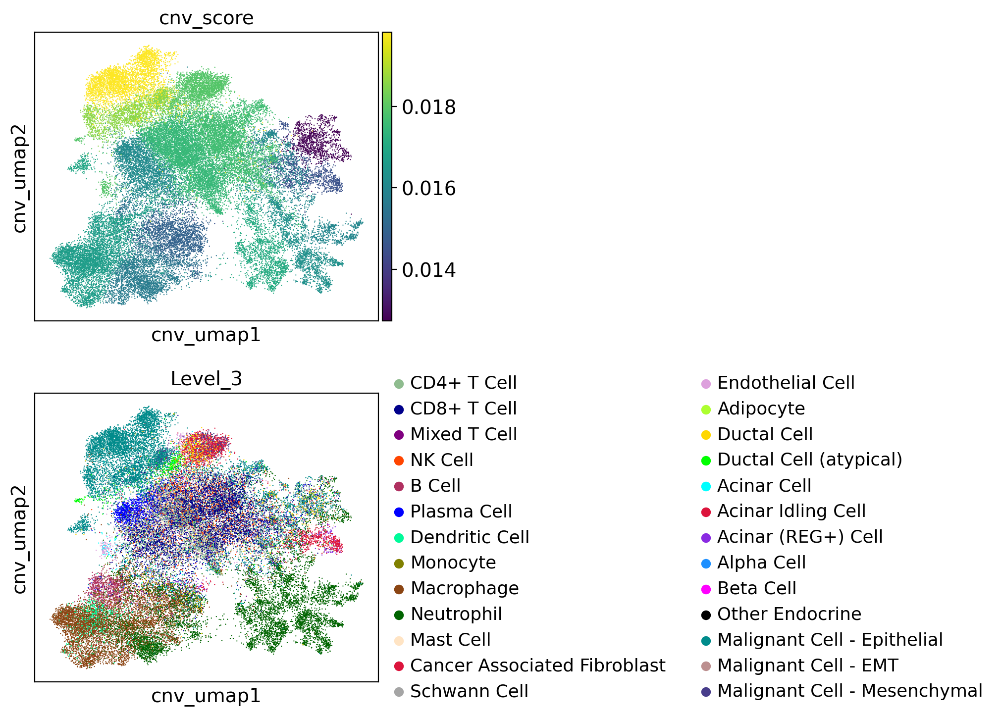

Finished processing dataset Steele_2020_scRNA-seq
Processing dataset Peng_2019_scRNA-seq
Inferring CNVs for Peng_2019_scRNA-seq


100%|██████████| 12/12 [00:14<00:00,  1.23s/it]


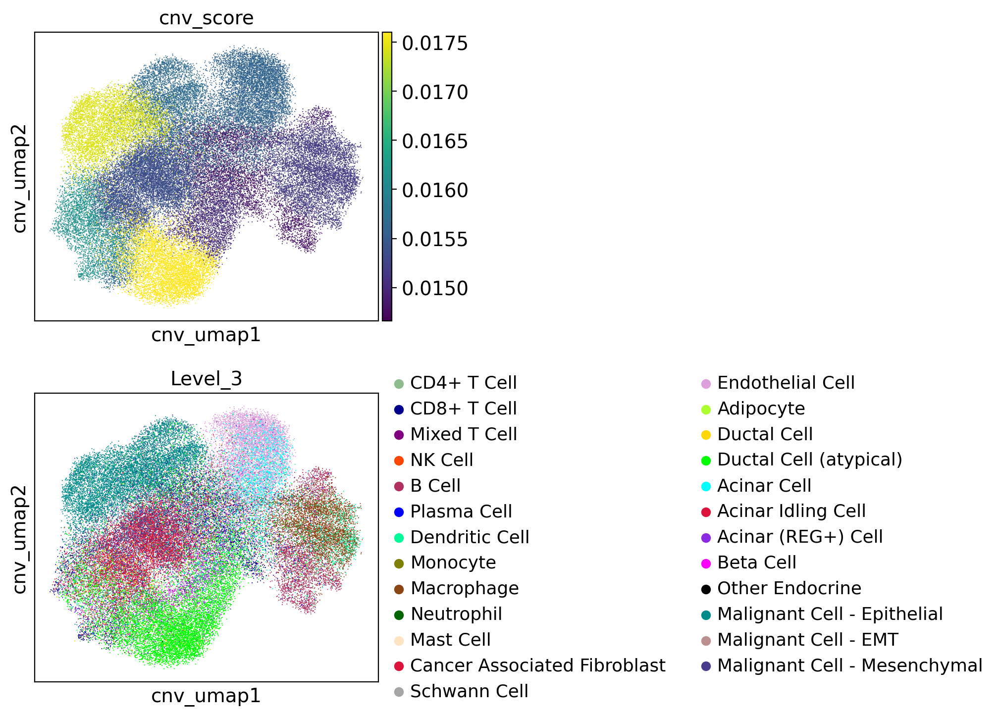

Finished processing dataset Peng_2019_scRNA-seq
Processing dataset Caronni_2023_scRNA-seq
Inferring CNVs for Caronni_2023_scRNA-seq


100%|██████████| 15/15 [00:15<00:00,  1.06s/it]


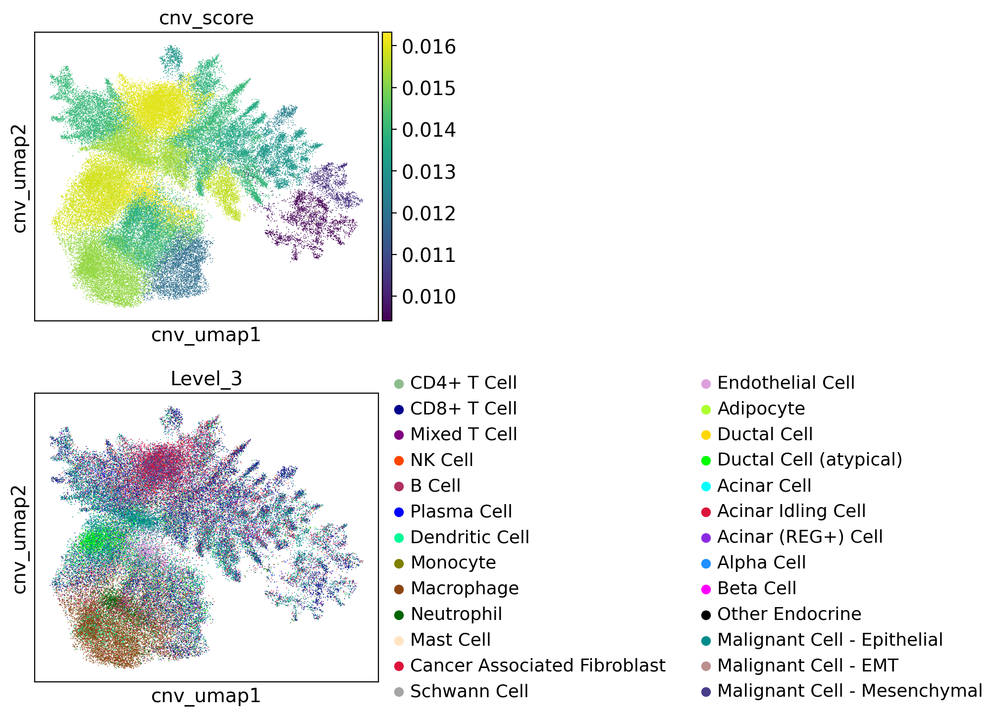

Finished processing dataset Caronni_2023_scRNA-seq
Processing dataset Lin_2020_scRNA-seq
Inferring CNVs for Lin_2020_scRNA-seq


100%|██████████| 2/2 [00:09<00:00,  4.61s/it]


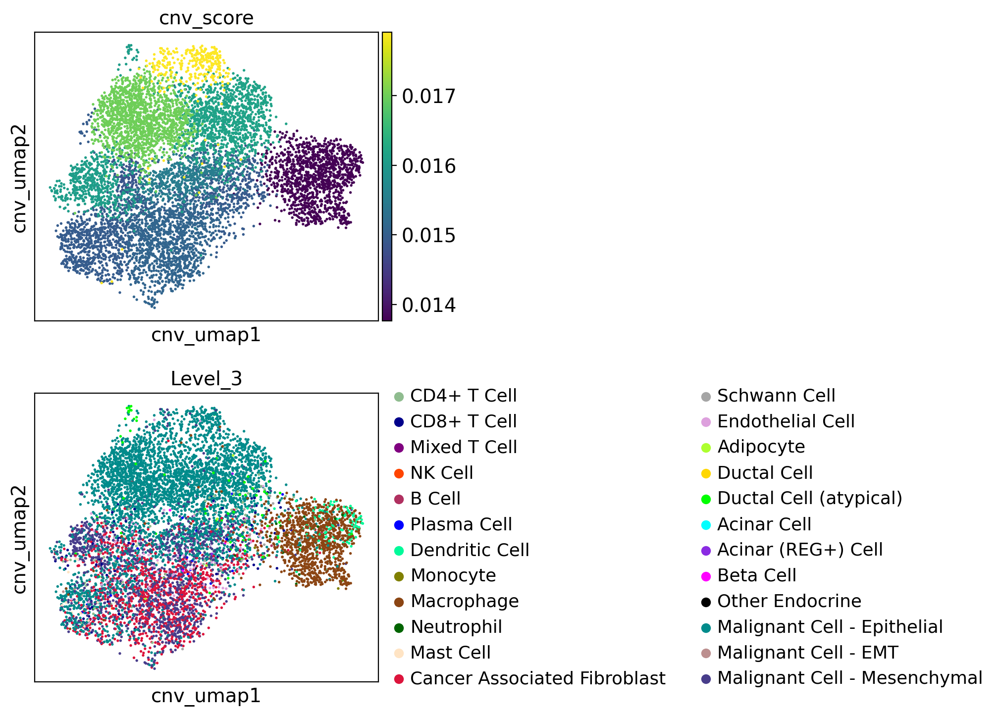

Finished processing dataset Lin_2020_scRNA-seq
Processing dataset Schlesinger_2020_scRNA-seq
Inferring CNVs for Schlesinger_2020_scRNA-seq


100%|██████████| 2/2 [00:07<00:00,  3.82s/it]


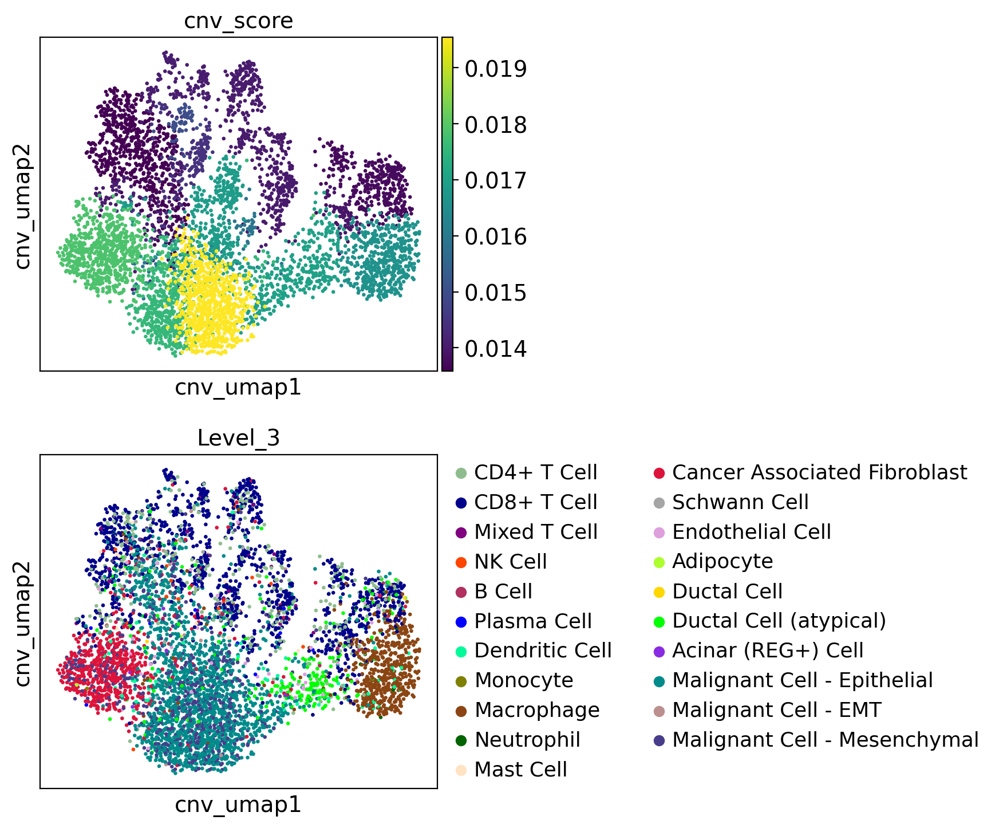

Finished processing dataset Schlesinger_2020_scRNA-seq
Processing dataset Hwang_2022_snRNA-seq
Inferring CNVs for Hwang_2022_snRNA-seq


100%|██████████| 38/38 [00:37<00:00,  1.00it/s]


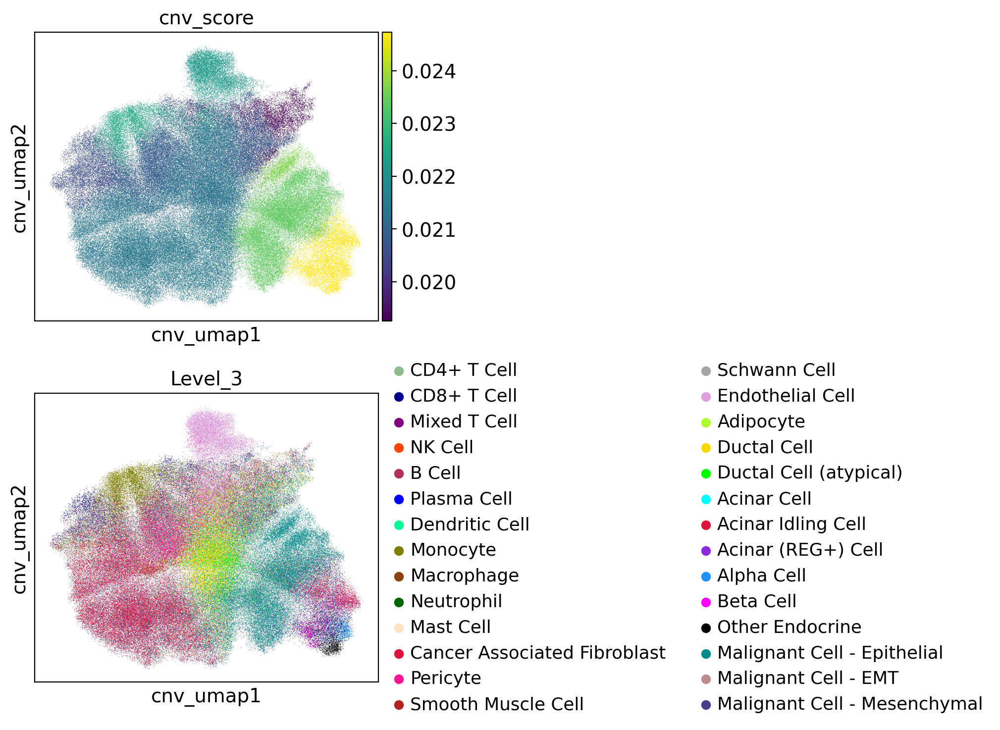

Finished processing dataset Hwang_2022_snRNA-seq
Processing dataset Ding_2022_snRNA-seq
Inferring CNVs for Ding_2022_snRNA-seq


100%|██████████| 12/12 [00:18<00:00,  1.52s/it]


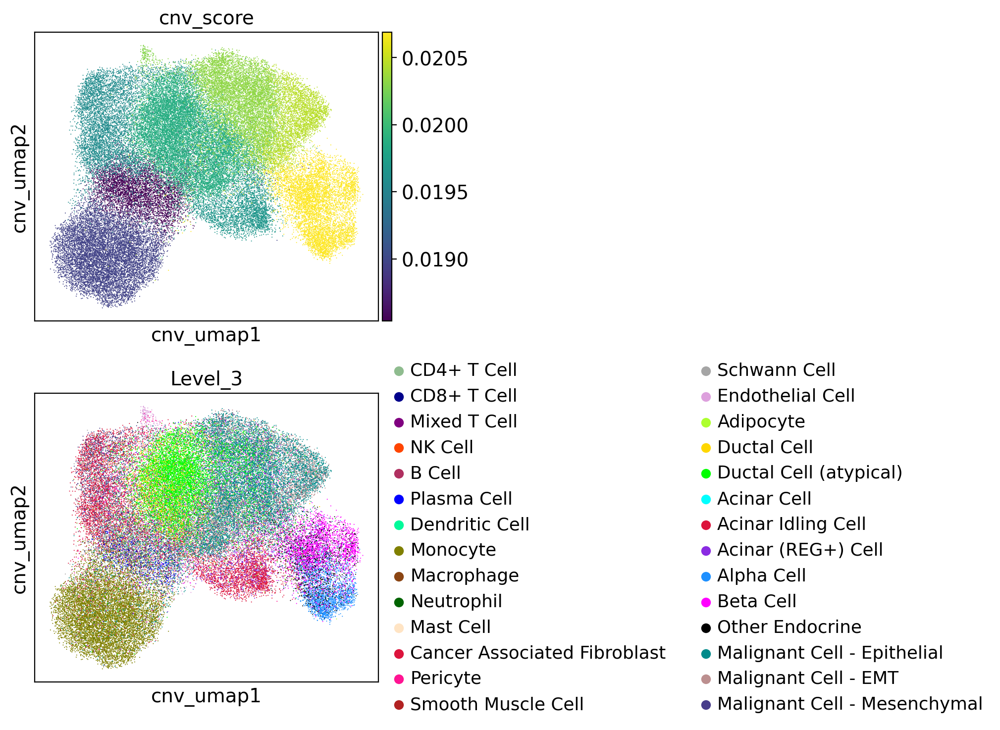

Finished processing dataset Ding_2022_snRNA-seq
Processing dataset Kemp_2020_scRNA-seq
Inferring CNVs for Kemp_2020_scRNA-seq


100%|██████████| 1/1 [00:04<00:00,  4.63s/it]


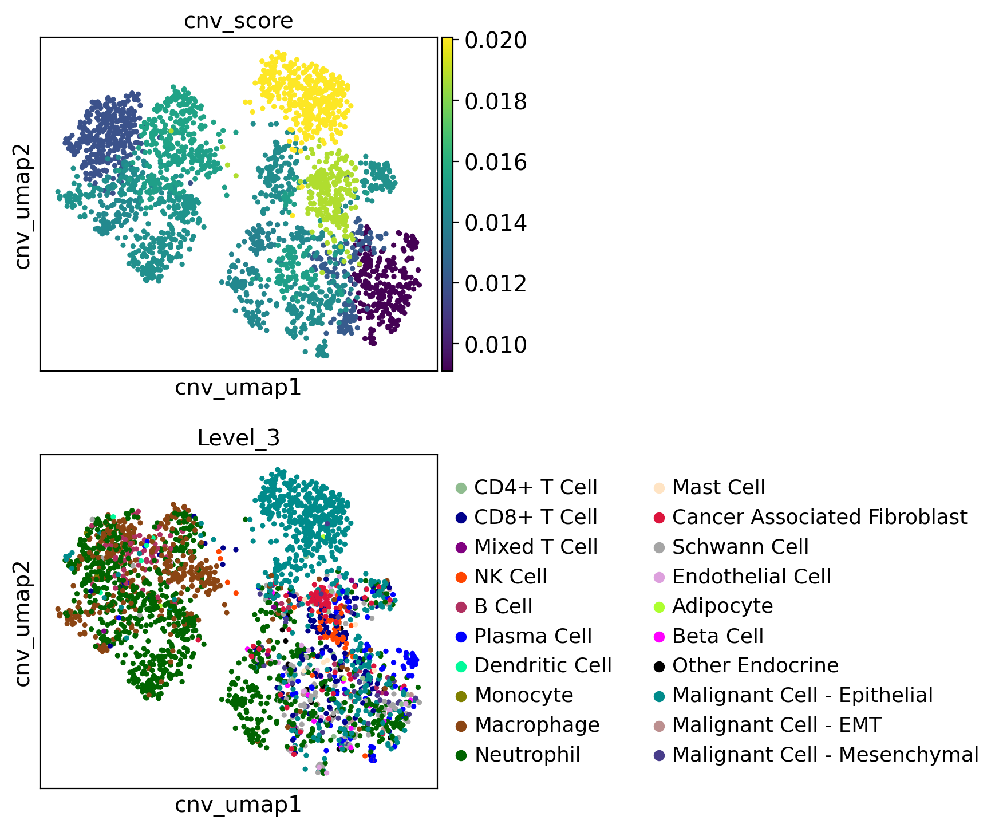

Finished processing dataset Kemp_2020_scRNA-seq
Processing dataset Yue_2020_scRNA-seq
Inferring CNVs for Yue_2020_scRNA-seq


100%|██████████| 16/16 [00:18<00:00,  1.16s/it]


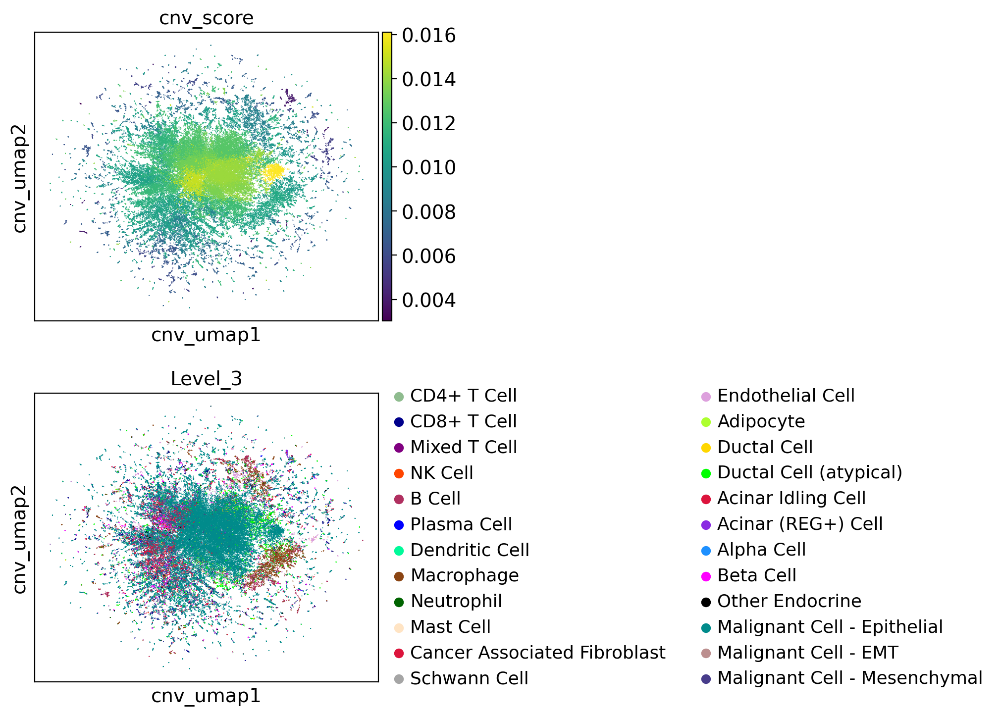

Finished processing dataset Yue_2020_scRNA-seq
Completed aggregation into cnv_score_dfs and updated adata_core.obs['cnv_score'].


In [13]:
cnv_score_dfs = {}
ref_subset_dict = {}

try:
    adata_core.obs['cnv_score'] = np.nan

    for dataset in adata_core.obs.Dataset_Tech.unique():
        print(f'Processing dataset {dataset}')
        ref_subset = adata_core[adata_core.obs['Dataset_Tech'] == dataset]

        sc.pp.filter_genes(ref_subset, min_cells=5)
        ref_subset.var['start'] = ref_subset.var.index.map(lambda x: dict_map[x][0] if x in dict_map else None)
        ref_subset.var['end'] = ref_subset.var.index.map(lambda x: dict_map[x][1] if x in dict_map else None)
        ref_subset.var['chromosome'] = ref_subset.var.index.map(lambda x: dict_map[x][2] if x in dict_map else None)
        ref_subset.var['chromosome'] = 'chr' + ref_subset.var['chromosome']

        pot_malignant_cells = ["Malignant Cell - Epithelial", "Malignant Cell - Mesenchymal", "Malignant Cell - EMT", "Ductal Cell (atypical)", ]
        ref_subset.obs["Reference"] = np.where(ref_subset.obs.Level_3.isin(pot_malignant_cells), 'Potentially Malignant', 'Reference')
        # Normalize, log transform, and perform dimensionality reduction
        sc.pp.normalize_total(ref_subset, target_sum=1e4)
        sc.pp.log1p(ref_subset)

        print(f'Inferring CNVs for {dataset}')
        # Run inferCNV
        cnv.tl.infercnv(
            ref_subset,
            reference_key="Reference",
            reference_cat="Reference",
            window_size=150,
        )

        # PCA and neighbor graph for CNV data
        cnv.tl.pca(ref_subset)
        cnv.pp.neighbors(ref_subset)
        cnv.tl.leiden(ref_subset)

        # Run UMAP and CNV scoring
        cnv.tl.umap(ref_subset)
        cnv.tl.cnv_score(ref_subset)

        # sc.pp.pca(ref_subset)
        # sc.pp.neighbors(ref_subset)
        # sc.tl.umap(ref_subset)
        # sc.tl.leiden(ref_subset)

        # Collect cell barcodes (index) and cnv_score into dataframe
        df = ref_subset.obs[['cnv_score']].copy()
        df['barcode'] = df.index
        cnv_score_dfs[dataset] = df[['barcode', 'cnv_score']].reset_index(drop=True)

        # Assign CNV scores back to the main adata_core object
        adata_core.obs.loc[df['barcode'], 'cnv_score'] = df['cnv_score'].values

        cnv.pl.umap(
            ref_subset,
            color=['cnv_score', 'Level_3'],
            ncols=1,
            save=f"_{dataset}_umap_cnvscore_level3.png"
        )
   
        ref_subset_dict[dataset] = ref_subset  # Save ref_subset in dict
        print('Finished processing dataset', dataset)
    print("Completed aggregation into cnv_score_dfs and updated adata_core.obs['cnv_score'].")
except Exception as e:
    print(f"An error occurred processing {dataset}")
    traceback.print_exc()

In [16]:
adata_core

AnnData object with n_obs × n_vars = 804862 × 39041
    obs: 'Sample_ID', 'Condition', 'Treatment', 'TreatmentType', 'TreatmentStatus', 'Tissue', 'Sex', 'Dataset', 'Technology', 'Level_1', 'Level_2', 'Level_3', 'Level_4', 'Age', 'Diabetes', 'Is_Core', 'EMT category', 'Dataset_ID', 'Cluster_Names', 'mal_vs_healthy', 'neuronal_markers', 'mesenchymal_ecm_markers', 'er_stress_markers', 'oncogenic_markers', 'Dataset_Tech', 'cnv_score'
    var: 'n_cells', 'ensembl_id', 'start', 'end', 'chromosome', 'gene_name_adata_sc', 'highly_variable_adata_sc', 'means_adata_sc', 'dispersions_adata_sc', 'dispersions_norm_adata_sc', 'highly_variable_nbatches_adata_sc', 'highly_variable_intersection_adata_sc', 'n_cells_by_counts_adata_sc', 'mean_counts_adata_sc', 'log1p_mean_counts_adata_sc', 'pct_dropout_by_counts_adata_sc', 'total_counts_adata_sc', 'log1p_total_counts_adata_sc', 'mito_adata_sc', 'n_cells_by_counts_adata_sn', 'mean_counts_adata_sn', 'log1p_mean_counts_adata_sn', 'pct_dropout_by_counts_adata

In [17]:
adata_core.obs.groupby('Dataset_Tech')['cnv_score'].mean()

Dataset_Tech
Caronni_2023_scRNA-seq        0.014357
Ding_2022_scRNA-seq           0.013693
Ding_2022_snRNA-seq           0.019755
Hwang_2022_snRNA-seq          0.021779
Kemp_2020_scRNA-seq           0.014757
Lee_2021_scRNA-seq            0.019897
Lin_2020_scRNA-seq            0.015556
Peng_2019_scRNA-seq           0.015866
Schlesinger_2020_scRNA-seq    0.016336
Simeone_2023_scRNA-seq        0.013268
Steele_2020_scRNA-seq         0.016925
Yue_2020_scRNA-seq            0.011382
Name: cnv_score, dtype: float64

In [19]:
from scipy.stats import zscore

# Z-score normalization of 'cnv_score' within each 'Dataset_Tech' group in adata_infercnv
adata_core.obs['cnv_score_z'] = (
    adata_core.obs.groupby('Dataset_Tech')['cnv_score']
    .transform(lambda x: zscore(x, nan_policy='omit'))
)

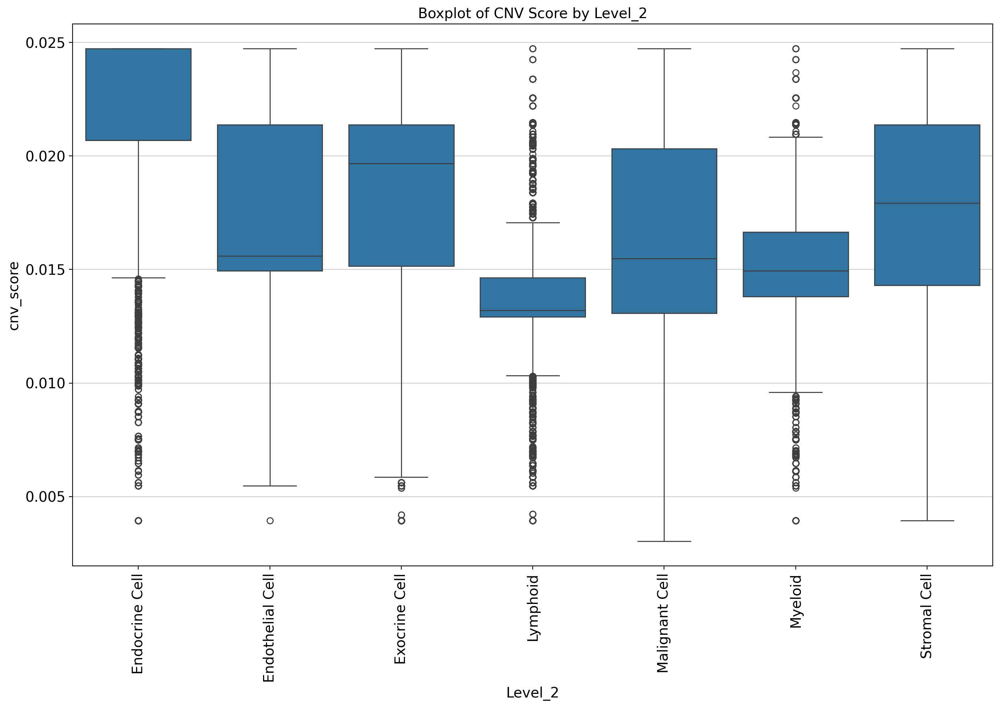

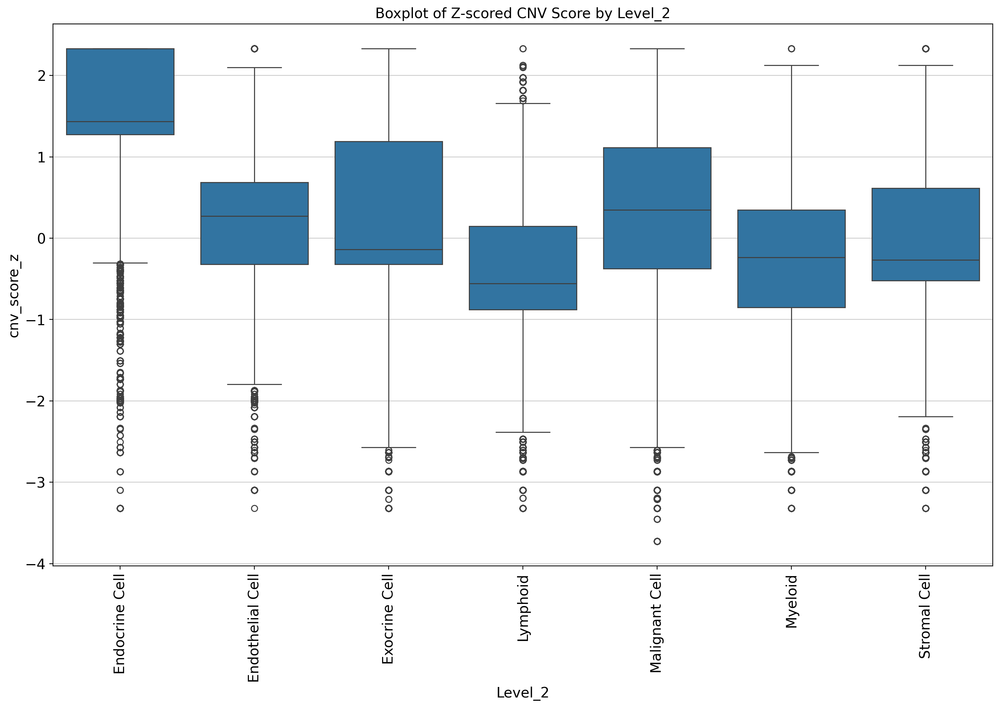

In [20]:
import seaborn as sns
plt.figure(figsize=(14,10))
sns.boxplot(x='Level_2', y='cnv_score', data=adata_core.obs)
plt.xticks(rotation=90)
plt.title("Boxplot of CNV Score by Level_2")
plt.tight_layout()
plt.show()
plt.figure(figsize=(14,10))
sns.boxplot(x='Level_2', y='cnv_score_z', data=adata_core.obs)
plt.xticks(rotation=90)
plt.title("Boxplot of Z-scored CNV Score by Level_2")
plt.tight_layout()
plt.show()

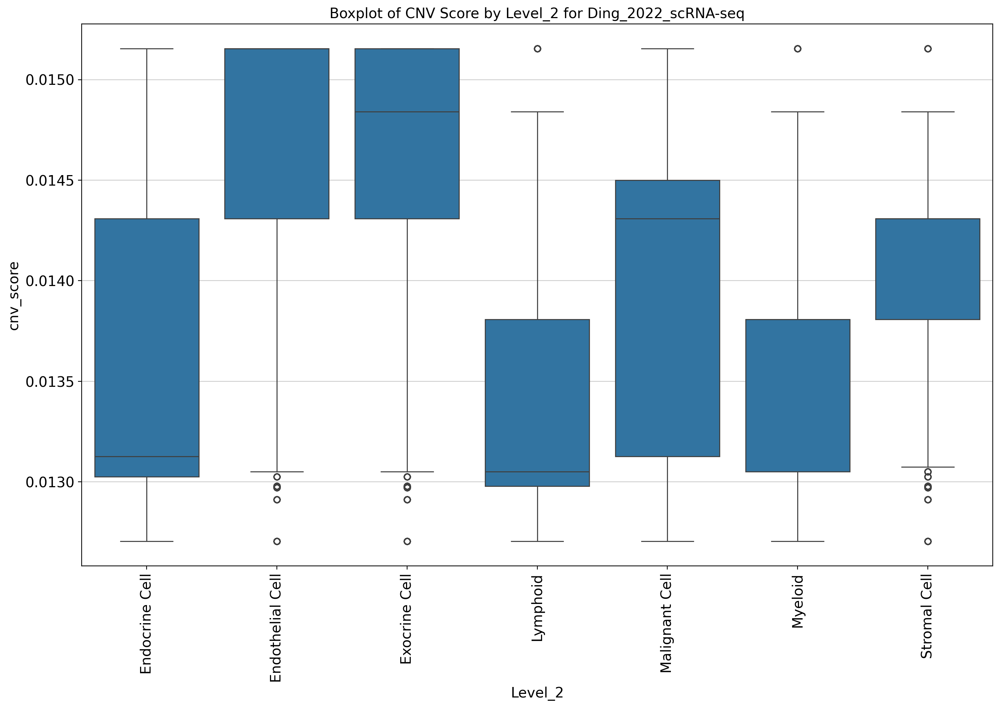

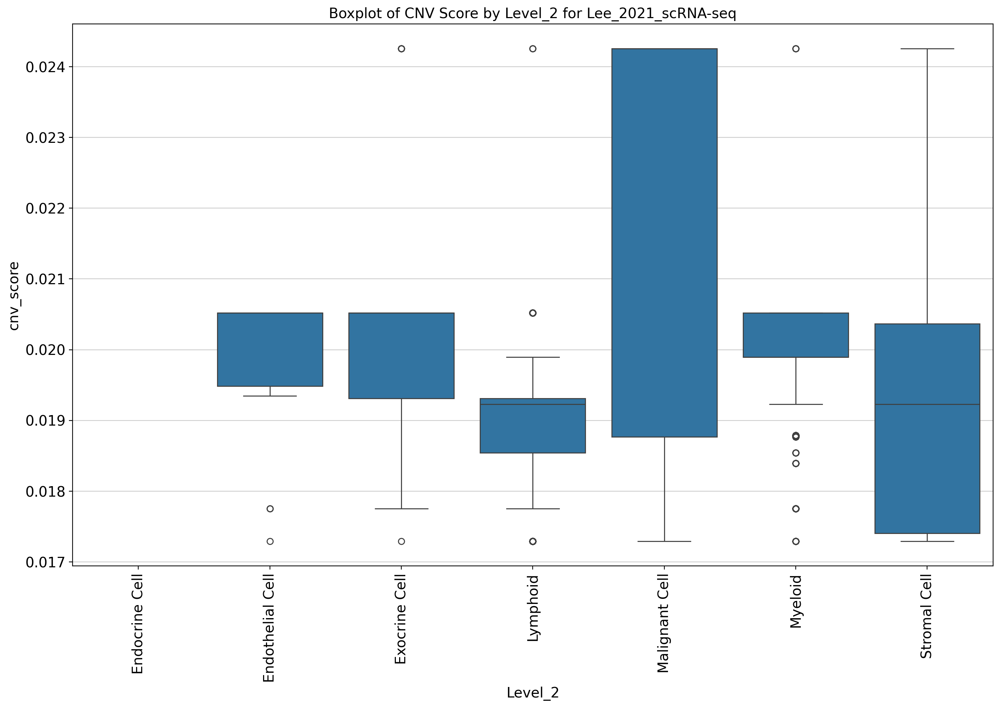

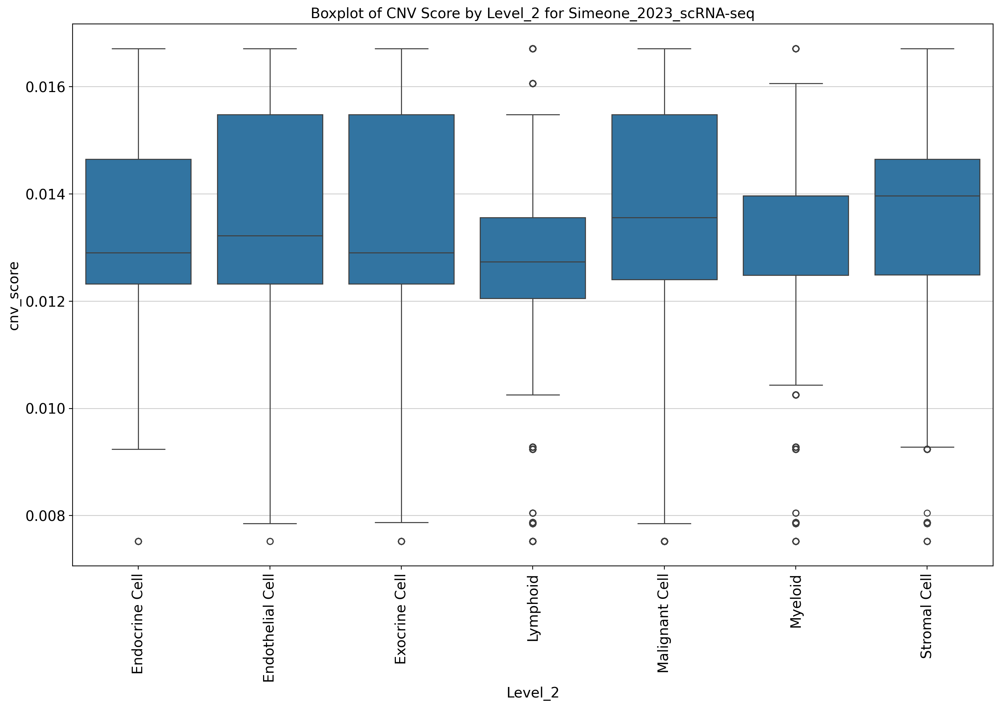

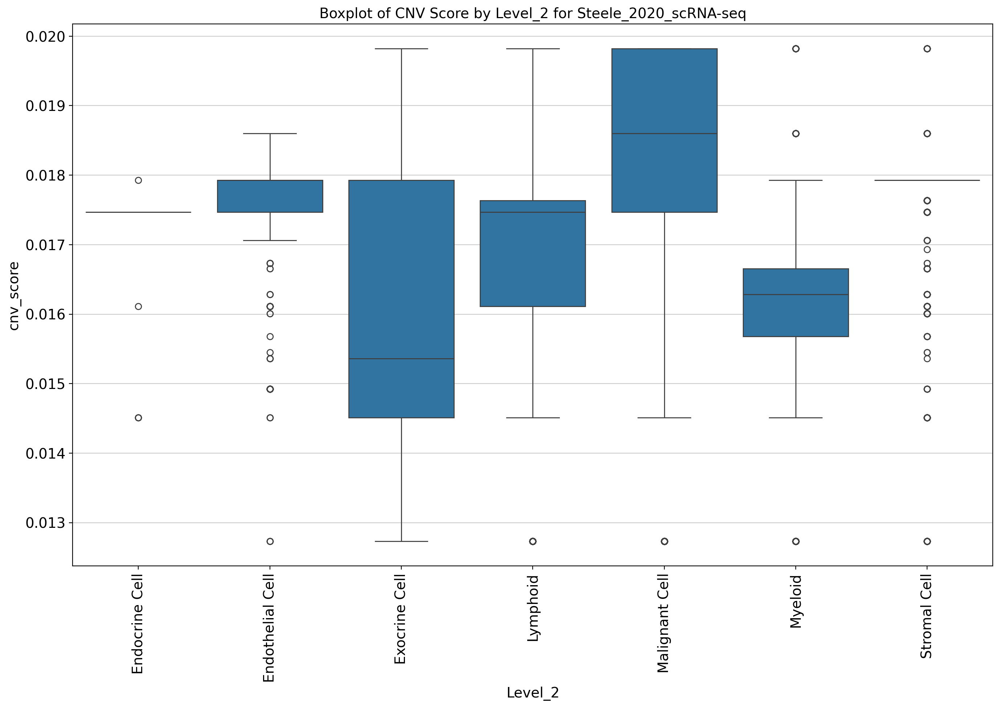

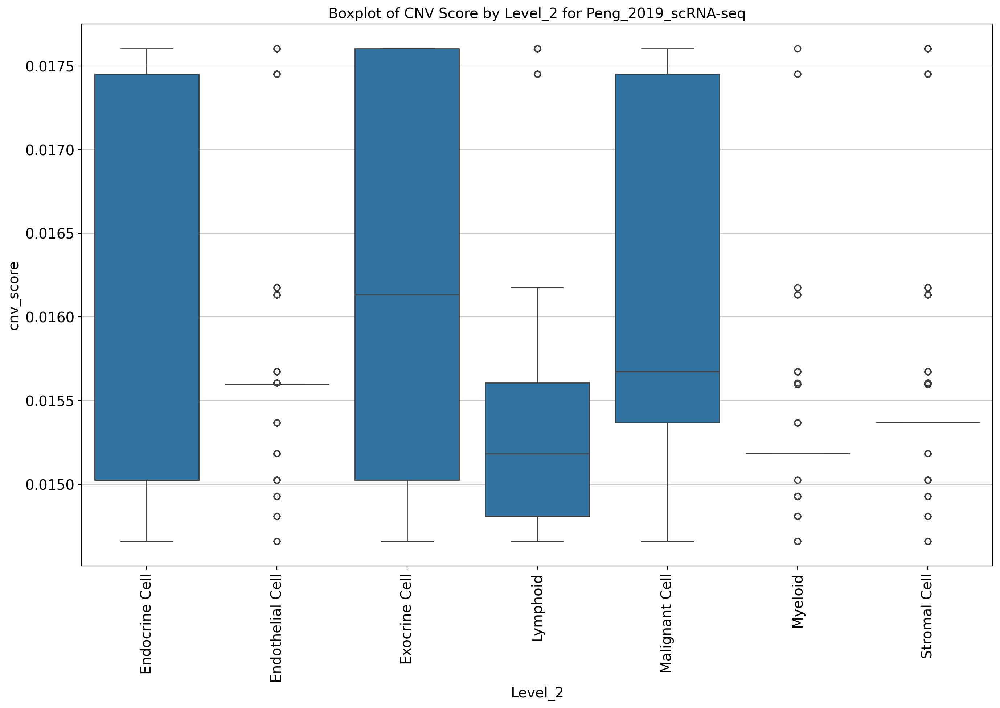

...

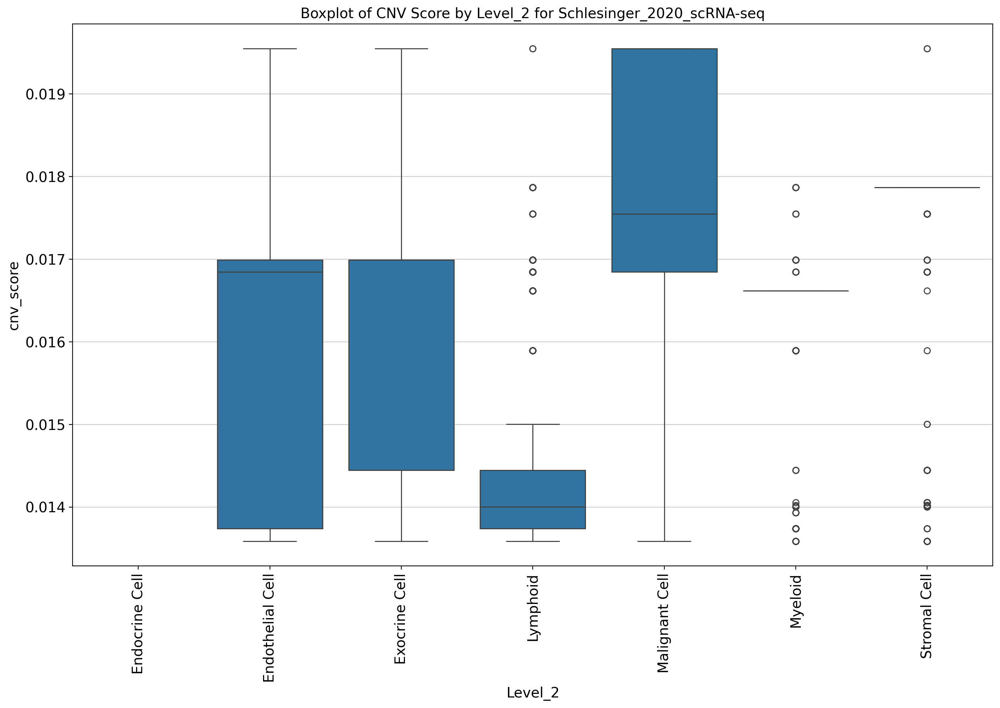

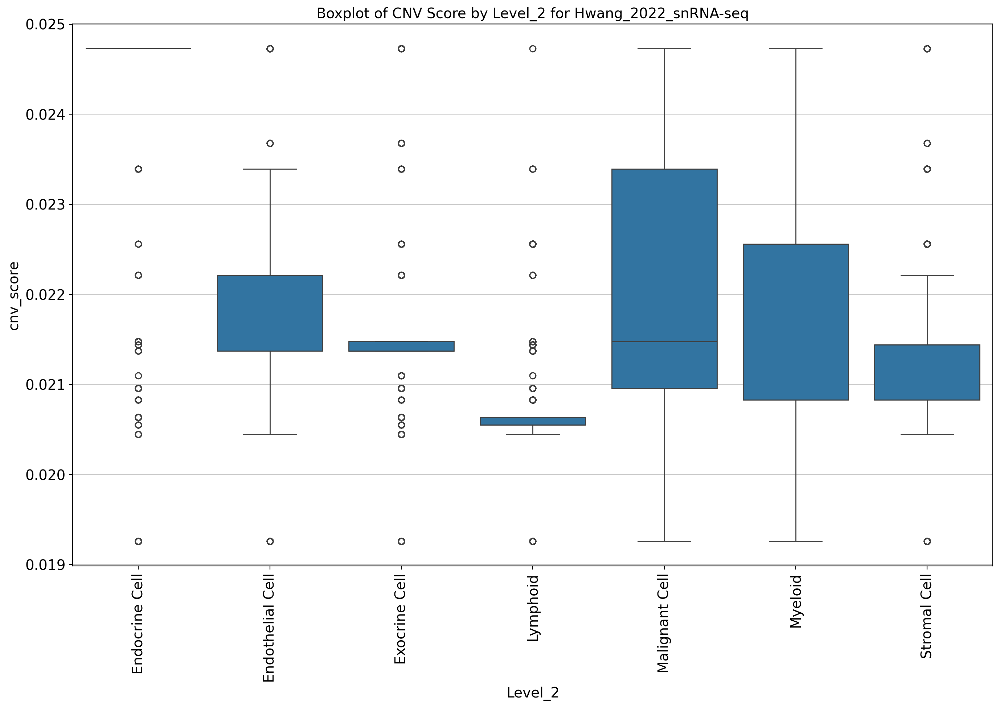

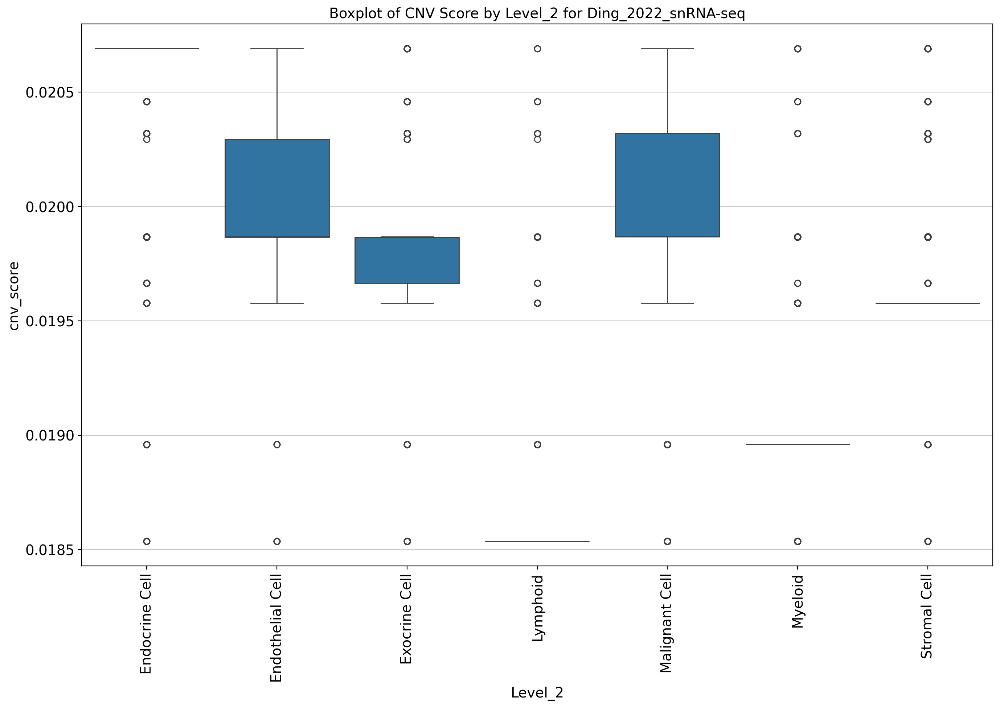

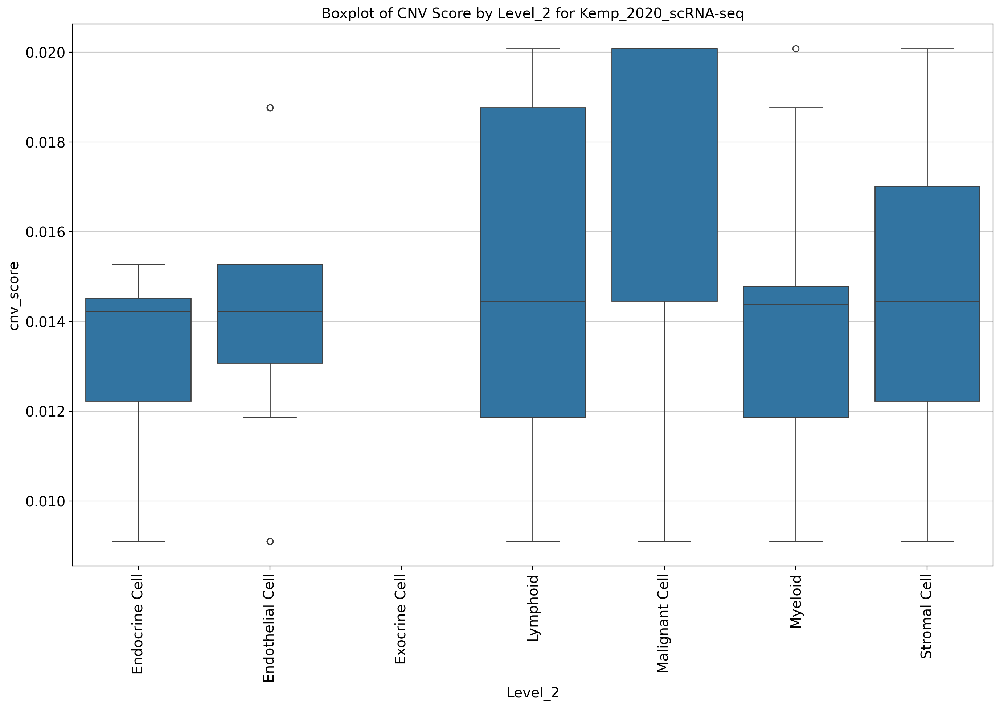

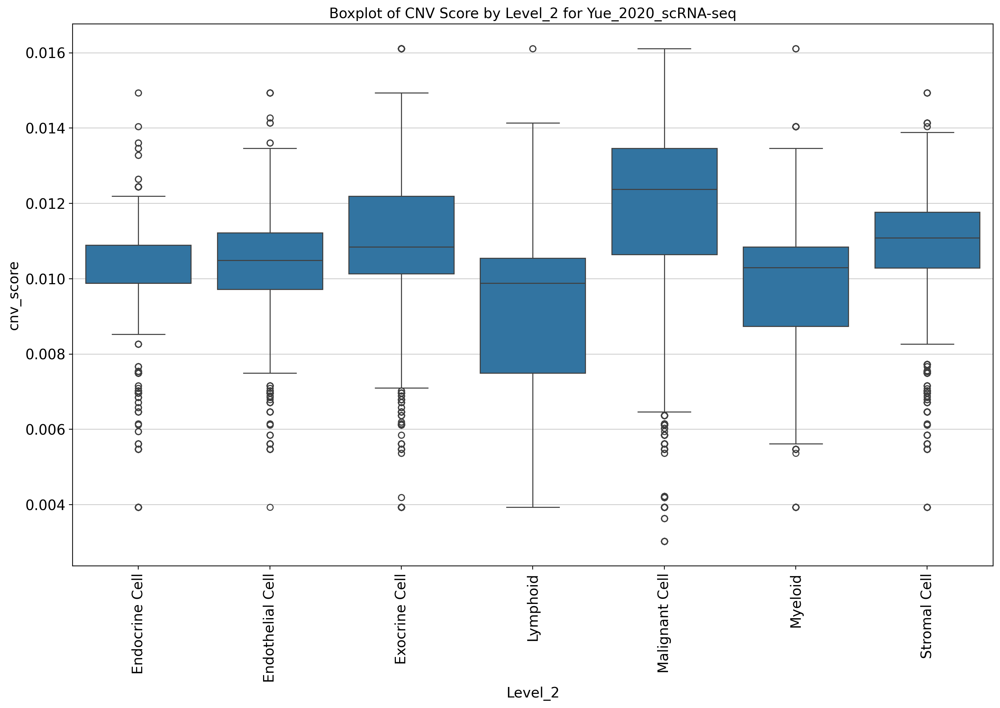

In [21]:
for dataset in adata_core.obs['Dataset_Tech'].unique():
    subset = adata_core.obs[adata_core.obs['Dataset_Tech'] == dataset]
    plt.figure(figsize=(14,10))
    sns.boxplot(x='Level_2', y='cnv_score', data=subset)
    plt.xticks(rotation=90)
    plt.title(f"Boxplot of CNV Score by Level_2 for {dataset}")
    plt.tight_layout()
    plt.show()

In [22]:
adata_core.obs[['cnv_score']].to_csv('cnv_score_per_dataset.csv')

<Axes: xlabel='Level_3', ylabel='cnv_score'>

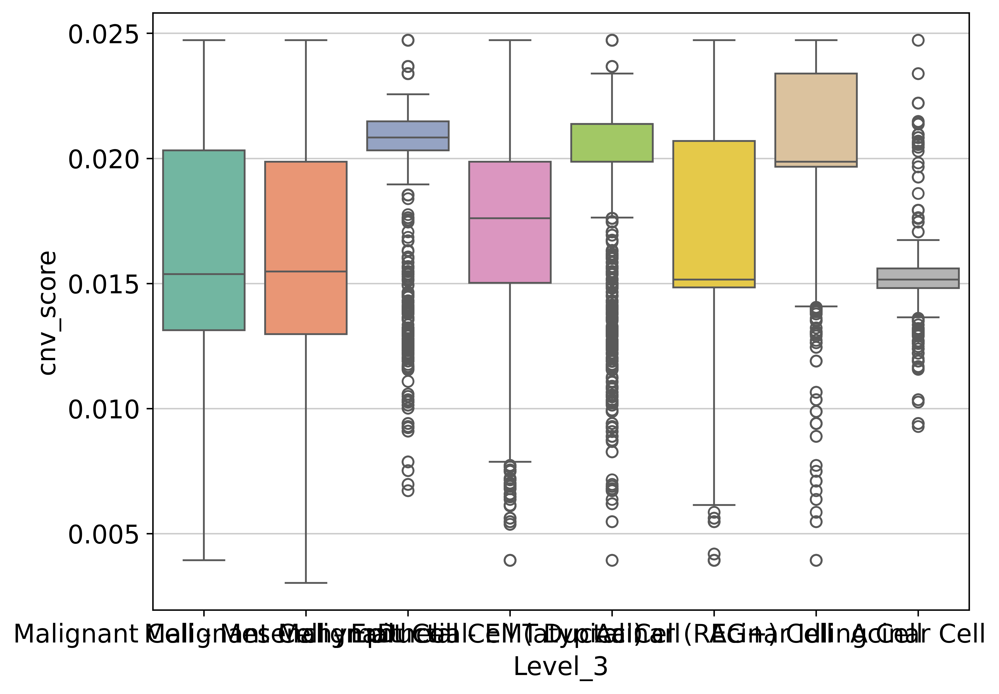

In [27]:

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
cell_types = [
    "Ductal Cell", "Ductal Cell (atypical)", "Acinar Cell", "Acinar Idling Cell", "Acinar (REG+) Cell",
    "Malignant Cell - Epithelial", "Malignant Cell - EMT", "Malignant Cell - Mesenchymal"
]
filtered_obs = adata_core.obs[adata_core.obs['Level_3'].isin(cell_types)].copy()
filtered_obs['Level_3'] = filtered_obs['Level_3'].astype(str)
sns.boxplot(
    x='Level_3',
    y='cnv_score',
    data=filtered_obs,
    palette='Set2',
    ax=ax
)


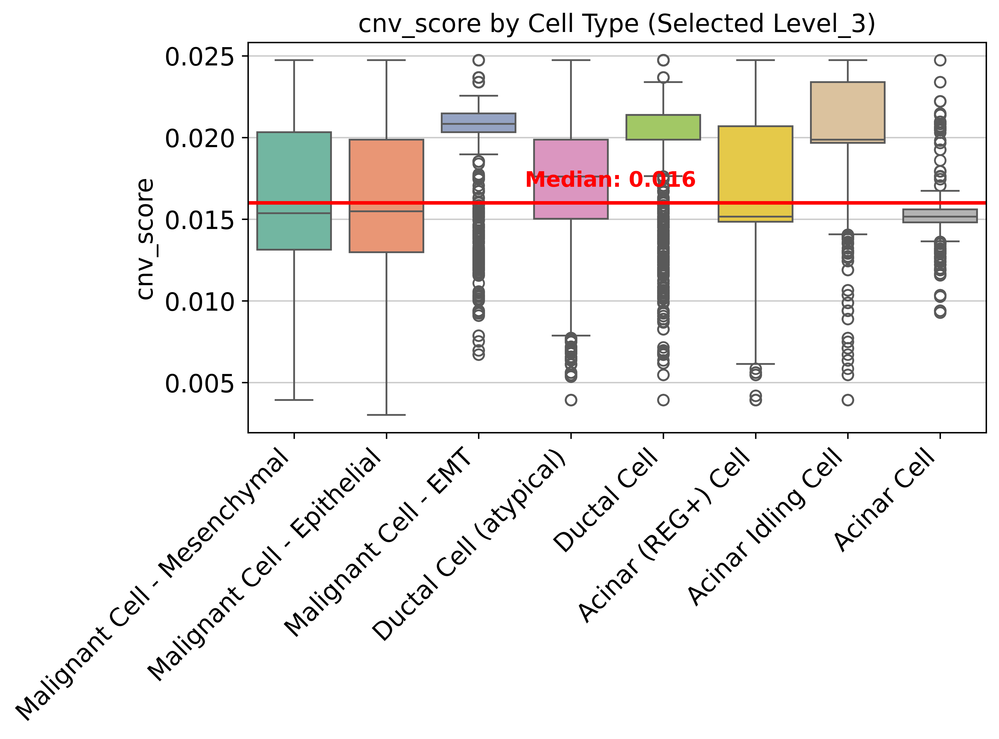

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
cell_types = [
    "Ductal Cell", "Ductal Cell (atypical)", "Acinar Cell", "Acinar Idling Cell", "Acinar (REG+) Cell",
    "Malignant Cell - Epithelial", "Malignant Cell - EMT", "Malignant Cell - Mesenchymal"
]
filtered_obs = adata_core.obs[adata_core.obs['Level_3'].isin(cell_types)].copy()
filtered_obs['Level_3'] = filtered_obs['Level_3'].astype(str)
sns.boxplot(
    x='Level_3',
    y='cnv_score',
    data=filtered_obs,
    palette='Set2',
    ax=ax
)

ax.set_ylabel("cnv_score")
ax.set_xlabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

# Calculate and plot the median
median_cnv = filtered_obs["cnv_score"].median()
ax.axhline(median_cnv, color='red', linestyle='-', linewidth=2)
ax.text(
    x=2.5,  # Horizontal position; tweak if needed for aesthetic
    y=median_cnv + 0.001,  # Slightly above the line
    s=f"Median: {median_cnv:.3f}",
    color='red',
    fontsize=12,
    fontweight='bold'
)

ax.set_title("cnv_score by Cell Type (Selected Level_3)")
fig.tight_layout()
fig.savefig("cnv_score_selected_Level3_boxplot.png", dpi=300)
plt.show()

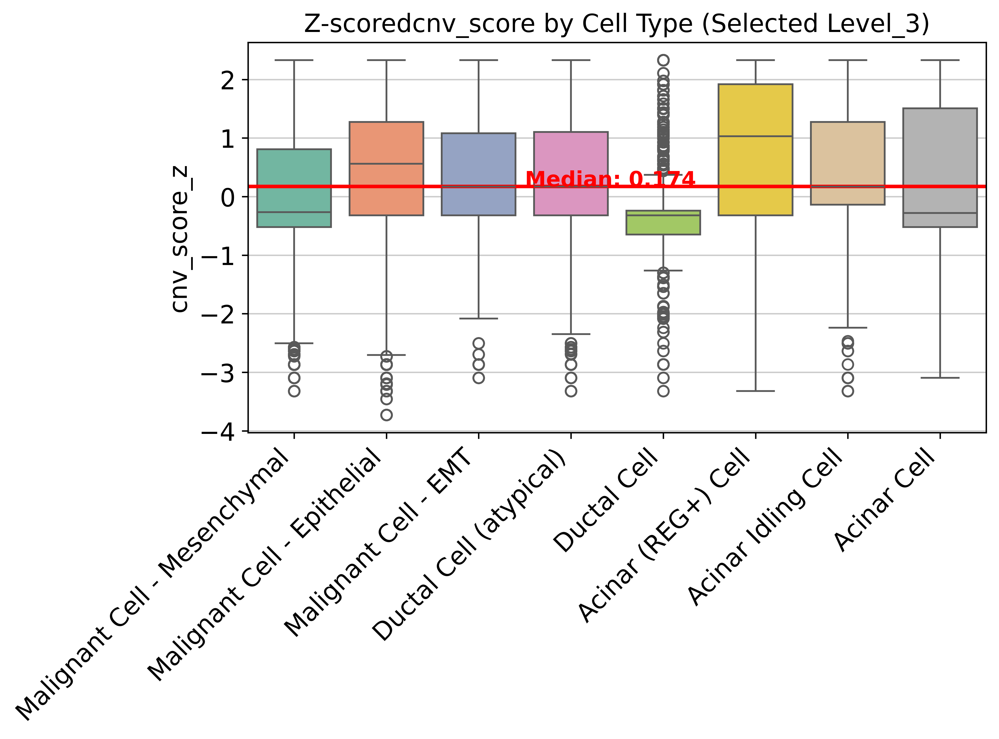

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
cell_types = [
    "Ductal Cell", "Ductal Cell (atypical)", "Acinar Cell", "Acinar Idling Cell", "Acinar (REG+) Cell",
    "Malignant Cell - Epithelial", "Malignant Cell - EMT", "Malignant Cell - Mesenchymal"
]
filtered_obs = adata_core.obs[adata_core.obs['Level_3'].isin(cell_types)].copy()
filtered_obs['Level_3'] = filtered_obs['Level_3'].astype(str)
sns.boxplot(
    x='Level_3',
    y='cnv_score_z',
    data=filtered_obs,
    palette='Set2',
    ax=ax
)

ax.set_ylabel("cnv_score_z")
ax.set_xlabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

# Calculate and plot the median
median_cnv = filtered_obs["cnv_score_z"].median()
ax.axhline(median_cnv, color='red', linestyle='-', linewidth=2)
ax.text(
    x=2.5,  # Horizontal position; tweak if needed for aesthetic
    y=median_cnv + 0.001,  # Slightly above the line
    s=f"Median: {median_cnv:.3f}",
    color='red',
    fontsize=12,
    fontweight='bold'
)

ax.set_title("Z-scoredcnv_score by Cell Type (Selected Level_3)")
fig.tight_layout()
fig.savefig("z_cnv_score_selected_Level3_boxplot.png", dpi=300)
plt.show()

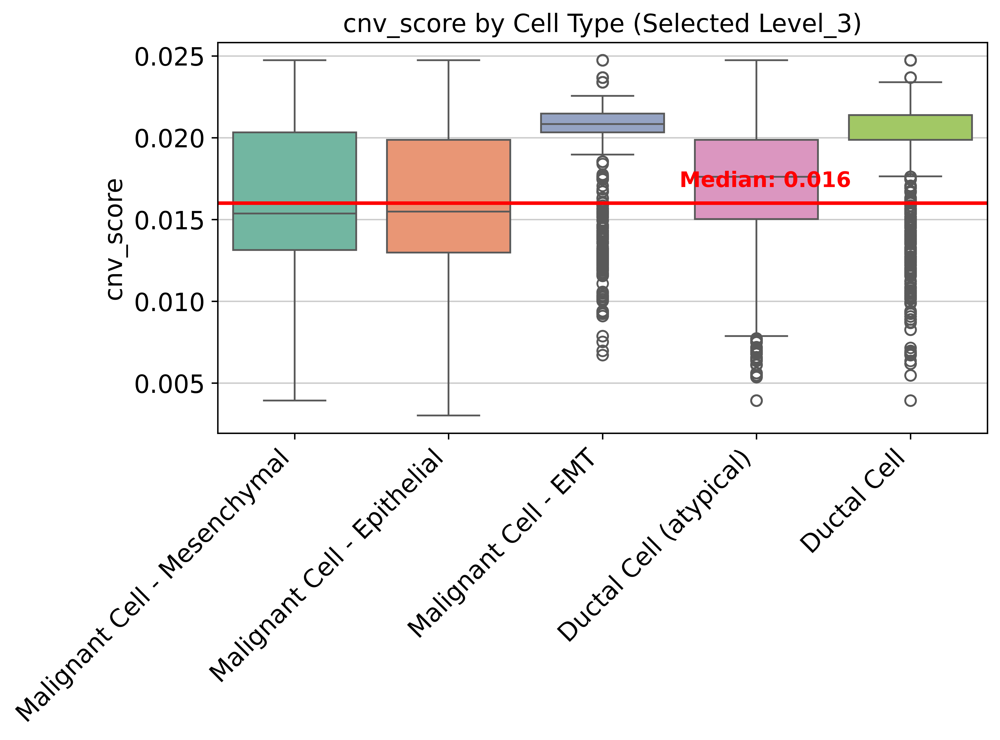

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
cell_types = [
    "Ductal Cell", "Ductal Cell (atypical)",
    "Malignant Cell - Epithelial", "Malignant Cell - EMT", "Malignant Cell - Mesenchymal"
]
filtered_obs = adata_core.obs[adata_core.obs['Level_3'].isin(cell_types)].copy()
filtered_obs['Level_3'] = filtered_obs['Level_3'].astype(str)
sns.boxplot(
    x='Level_3',
    y='cnv_score',
    data=filtered_obs,
    palette='Set2',
    ax=ax
)

ax.set_ylabel("cnv_score")
ax.set_xlabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

# Calculate and plot the median
median_cnv = filtered_obs["cnv_score"].median()
ax.axhline(median_cnv, color='red', linestyle='-', linewidth=2)
ax.text(
    x=2.5,  # Horizontal position; tweak if needed for aesthetic
    y=median_cnv + 0.001,  # Slightly above the line
    s=f"Median: {median_cnv:.3f}",
    color='red',
    fontsize=12,
    fontweight='bold'
)

ax.set_title("cnv_score by Cell Type (Selected Level_3)")
fig.tight_layout()
fig.savefig("ductal_cnv_score_selected_Level3_boxplot.png", dpi=300)
plt.show()

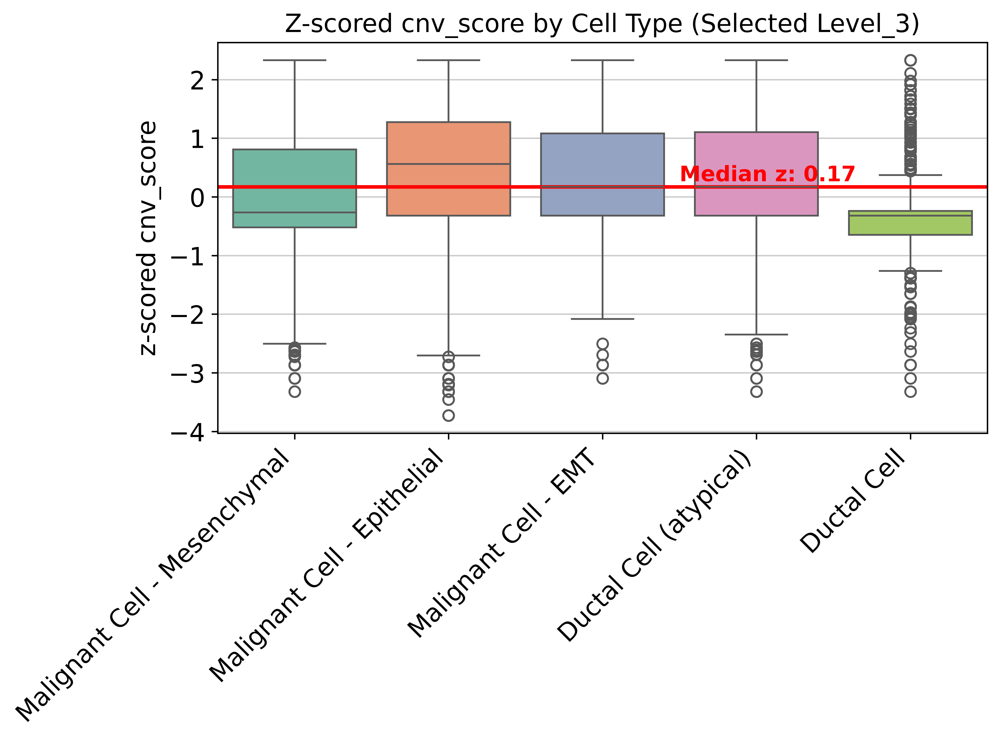

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
cell_types = [
    "Ductal Cell", "Ductal Cell (atypical)",
    "Malignant Cell - Epithelial", "Malignant Cell - EMT", "Malignant Cell - Mesenchymal"
]
filtered_obs = adata_core.obs[adata_core.obs['Level_3'].isin(cell_types)].copy()
filtered_obs['Level_3'] = filtered_obs['Level_3'].astype(str)


sns.boxplot(
    x='Level_3',
    y='cnv_score_z',
    data=filtered_obs,
    palette='Set2',
    ax=ax
)

ax.set_ylabel("z-scored cnv_score")
ax.set_xlabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

# Calculate and plot the global median of z-scores (should be ~0)
median_cnv_z = filtered_obs["cnv_score_z"].median()
ax.axhline(median_cnv_z, color='red', linestyle='-', linewidth=2)
ax.text(
    x=2.5,  # Horizontal position; tweak if needed for aesthetic
    y=median_cnv_z + 0.1,  # Slightly above the line; larger margin for z-score
    s=f"Median z: {median_cnv_z:.2f}",
    color='red',
    fontsize=12,
    fontweight='bold'
)

ax.set_title("Z-scored cnv_score by Cell Type (Selected Level_3)")
fig.tight_layout()
fig.savefig("ductal_z_cnv_score_selected_Level3_boxplot.png", dpi=300)
plt.show()

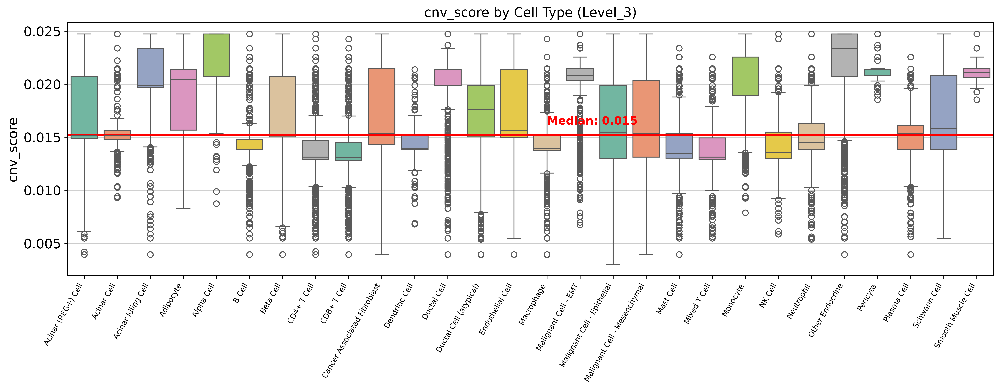

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, ax = plt.subplots(figsize=(15, 6), dpi=300)

# Use all unique cell types in Level_3, sorted alphabetically
all_cell_types = sorted(adata_core.obs["Level_3"].astype(str).unique())
filtered_obs = adata_core.obs.copy()
filtered_obs['Level_3'] = filtered_obs['Level_3'].astype(str)
filtered_obs = filtered_obs.loc[filtered_obs['Level_3'].isin(all_cell_types)]

sns.boxplot(
    x='Level_3',
    y='cnv_score',
    data=filtered_obs,
    order=all_cell_types,  # Ensure alphabetical order
    palette='Set2',
    ax=ax
)

ax.set_ylabel("cnv_score")
ax.set_xlabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=60, ha='right', fontsize=8)

# Calculate and plot the global median
median_cnv = filtered_obs["cnv_score"].median()
ax.axhline(median_cnv, color='red', linestyle='-', linewidth=2)
ax.text(
    x=len(all_cell_types) / 2,  # Centered
    y=median_cnv + 0.001,  # Slightly above the line
    s=f"Median: {median_cnv:.3f}",
    color='red',
    fontsize=12,
    fontweight='bold'
)

ax.set_title("cnv_score by Cell Type (Level_3)")
fig.tight_layout()
fig.savefig("all_level3_cnv_score_boxplot.png", dpi=300)
plt.show()

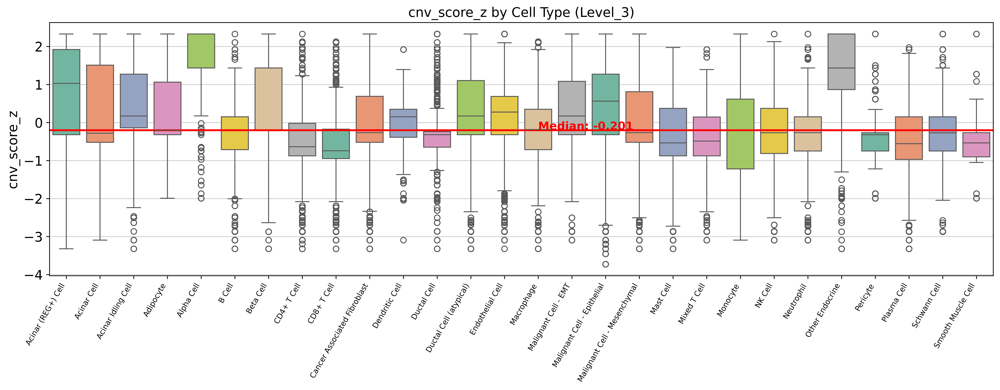

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, ax = plt.subplots(figsize=(15, 6), dpi=300)

# Use all unique cell types in Level_3, sorted alphabetically
all_cell_types = sorted(adata_core.obs["Level_3"].astype(str).unique())
filtered_obs = adata_core.obs.copy()
filtered_obs['Level_3'] = filtered_obs['Level_3'].astype(str)
filtered_obs = filtered_obs.loc[filtered_obs['Level_3'].isin(all_cell_types)]

sns.boxplot(
    x='Level_3',
    y='cnv_score_z',
    data=filtered_obs,
    order=all_cell_types,  # Ensure alphabetical order
    palette='Set2',
    ax=ax
)

ax.set_ylabel("cnv_score_z")
ax.set_xlabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=60, ha='right', fontsize=8)

# Calculate and plot the global median
median_cnv_z = filtered_obs["cnv_score_z"].median()
ax.axhline(median_cnv_z, color='red', linestyle='-', linewidth=2)
ax.text(
    x=len(all_cell_types) / 2,  # Centered
    y=median_cnv_z + 0.01,  # Slightly above the line (adjust if needed)
    s=f"Median: {median_cnv_z:.3f}",
    color='red',
    fontsize=12,
    fontweight='bold'
)

ax.set_title("cnv_score_z by Cell Type (Level_3)")
fig.tight_layout()
fig.savefig("all_level3_cnv_score_z_boxplot.png", dpi=300)
plt.show()

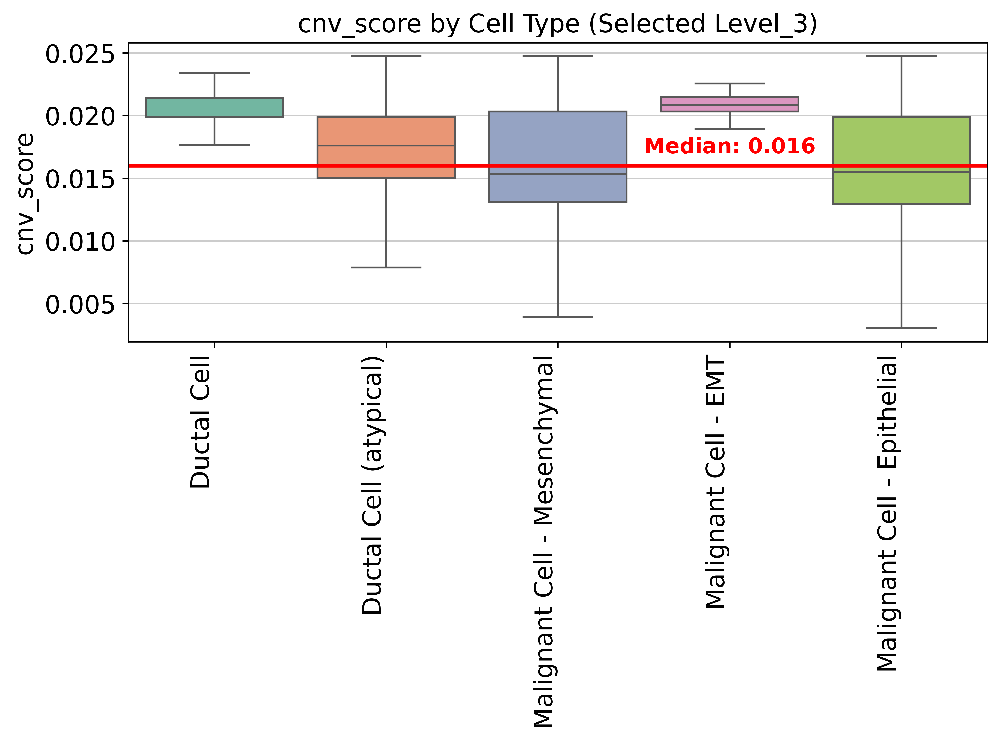

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

# Inverted order: Ductal > Atypical > Malignants
cell_types = [
    "Ductal Cell", "Ductal Cell (atypical)",
    "Malignant Cell - Mesenchymal", "Malignant Cell - EMT", "Malignant Cell - Epithelial"
]

filtered_obs = adata_core.obs[adata_core.obs['Level_3'].isin(cell_types)].copy()
filtered_obs['Level_3'] = filtered_obs['Level_3'].astype(str)

# Remove outliers by using the 'showfliers=False' argument
sns.boxplot(
    x='Level_3',
    y='cnv_score',
    data=filtered_obs,
    order=cell_types,     # enforce explicit/inverted order
    palette='Set2',
    ax=ax,
    showfliers=False
)

ax.set_ylabel("cnv_score")
ax.set_xlabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha='right')

# Calculate and plot the median
median_cnv = filtered_obs["cnv_score"].median()
ax.axhline(median_cnv, color='red', linestyle='-', linewidth=2)
ax.text(
    x=2.5,  # Centered in the group
    y=median_cnv + 0.001,  # Slightly above the line
    s=f"Median: {median_cnv:.3f}",
    color='red',
    fontsize=12,
    fontweight='bold'
)

ax.set_title("cnv_score by Cell Type (Selected Level_3)")
fig.tight_layout()
fig.savefig("ductal_cnv_score_selected_Level3_boxplot.png", dpi=300)
plt.show()

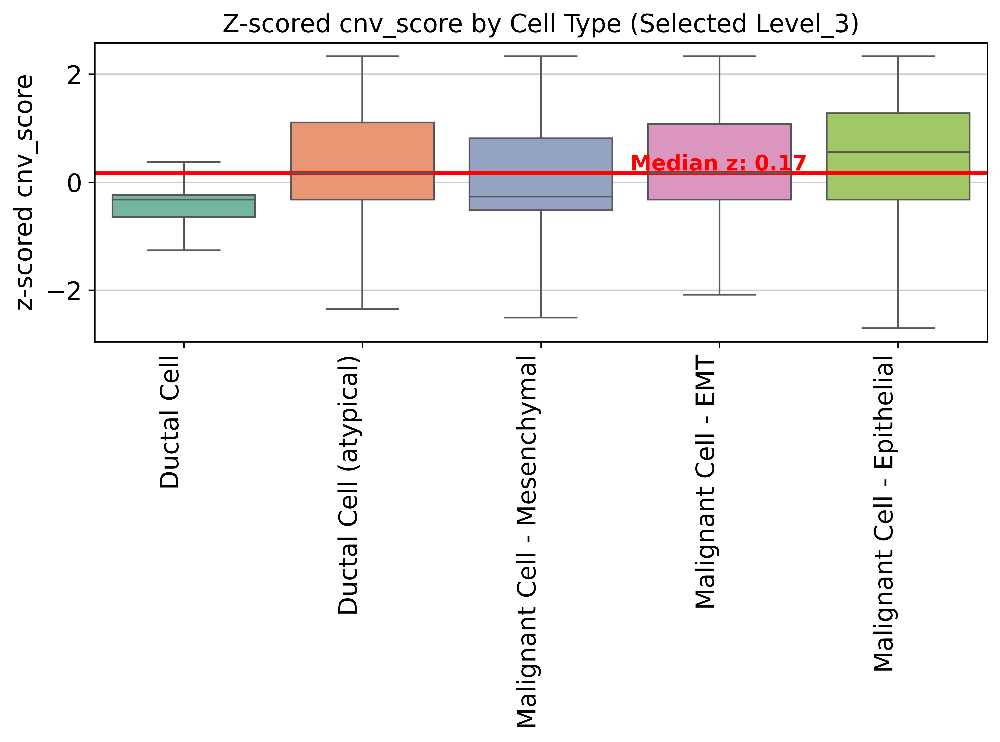

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

# Inverted order: Ductal > Atypical > Malignants (Epithelial, EMT, Mesenchymal)
cell_types = [
    "Ductal Cell", "Ductal Cell (atypical)",
    "Malignant Cell - Mesenchymal", "Malignant Cell - EMT", "Malignant Cell - Epithelial"
]

filtered_obs = adata_core.obs[adata_core.obs['Level_3'].isin(cell_types)].copy()
filtered_obs['Level_3'] = filtered_obs['Level_3'].astype(str)

# Remove outliers by using the 'showfliers=False' argument
sns.boxplot(
    x='Level_3',
    y='cnv_score_z',
    data=filtered_obs,
    order=cell_types,     # enforce explicit/inverted order
    palette='Set2',
    ax=ax,
    showfliers=False
)

ax.set_ylabel("z-scored cnv_score")
ax.set_xlabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha='right')

# Calculate and plot the median of z-scored cnv_scores
median_cnv_z = filtered_obs["cnv_score_z"].median()
ax.axhline(median_cnv_z, color='red', linestyle='-', linewidth=2)
ax.text(
    x=2.5,  # Centered in the group
    y=median_cnv_z + 0.05,  # Slightly above the line (smaller for z-scale)
    s=f"Median z: {median_cnv_z:.2f}",
    color='red',
    fontsize=12,
    fontweight='bold'
)

ax.set_title("Z-scored cnv_score by Cell Type (Selected Level_3)")
fig.tight_layout()
fig.savefig("ductal_z_cnv_score_selected_Level3_boxplot.png", dpi=300)
plt.show()

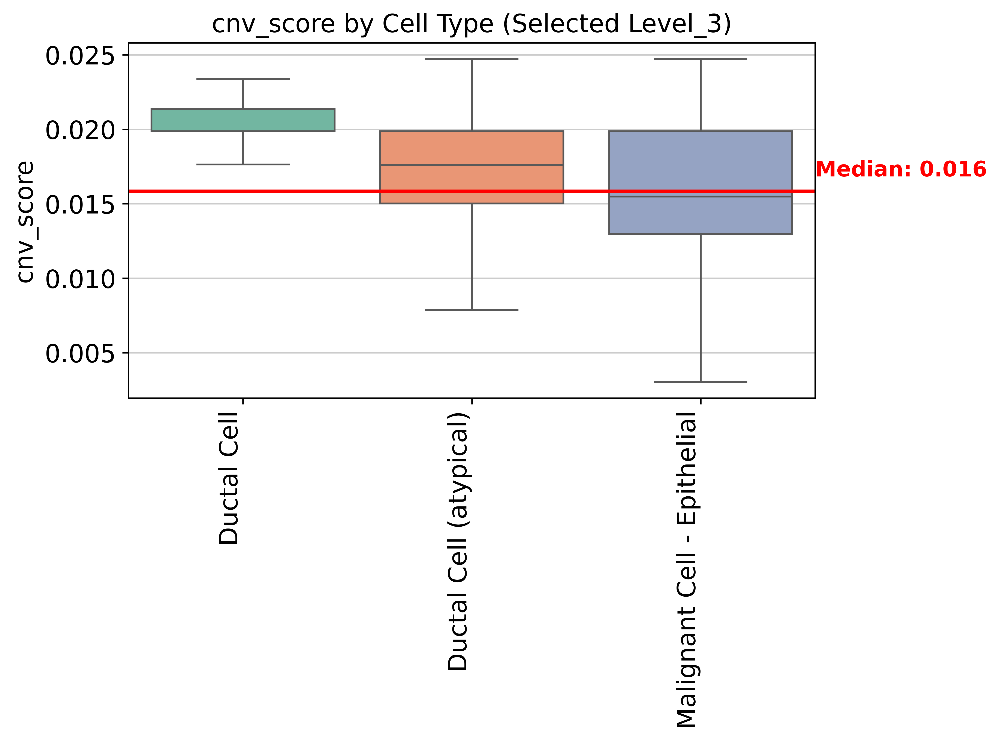

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

# Inverted order: Ductal > Atypical > Malignants
cell_types = [
    "Ductal Cell", "Ductal Cell (atypical)", "Malignant Cell - Epithelial"
]

filtered_obs = adata_core.obs[adata_core.obs['Level_3'].isin(cell_types)].copy()
filtered_obs['Level_3'] = filtered_obs['Level_3'].astype(str)

# Remove outliers by using the 'showfliers=False' argument
sns.boxplot(
    x='Level_3',
    y='cnv_score',
    data=filtered_obs,
    order=cell_types,     # enforce explicit/inverted order
    palette='Set2',
    ax=ax,
    showfliers=False
)

ax.set_ylabel("cnv_score")
ax.set_xlabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha='right')

# Calculate and plot the median
median_cnv = filtered_obs["cnv_score"].median()
ax.axhline(median_cnv, color='red', linestyle='-', linewidth=2)
ax.text(
    x=2.5,  # Centered in the group
    y=median_cnv + 0.001,  # Slightly above the line
    s=f"Median: {median_cnv:.3f}",
    color='red',
    fontsize=12,
    fontweight='bold'
)

ax.set_title("cnv_score by Cell Type (Selected Level_3)")
fig.tight_layout()
fig.savefig("epi_ductal_cnv_score_selected_Level3_boxplot.png", dpi=300)
plt.show()

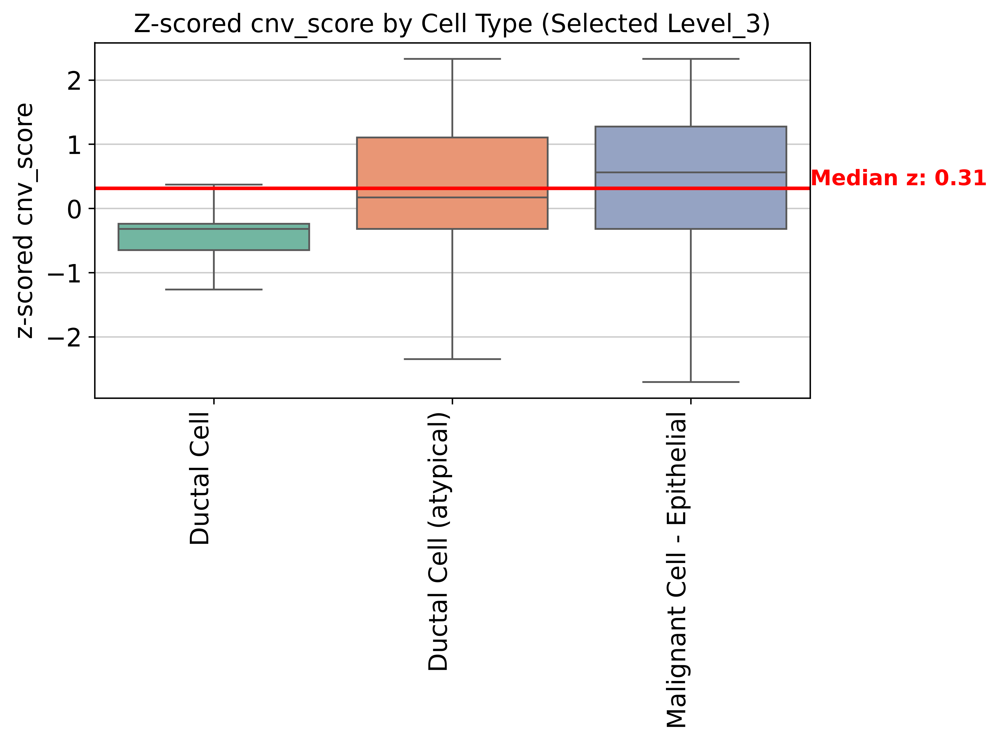

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

# Inverted order: Ductal > Atypical > Malignants (Epithelial, EMT, Mesenchymal)
cell_types = [
    "Ductal Cell", "Ductal Cell (atypical)", "Malignant Cell - Epithelial"
]

filtered_obs = adata_core.obs[adata_core.obs['Level_3'].isin(cell_types)].copy()
filtered_obs['Level_3'] = filtered_obs['Level_3'].astype(str)

# Remove outliers by using the 'showfliers=False' argument
sns.boxplot(
    x='Level_3',
    y='cnv_score_z',
    data=filtered_obs,
    order=cell_types,     # enforce explicit/inverted order
    palette='Set2',
    ax=ax,
    showfliers=False
)

ax.set_ylabel("z-scored cnv_score")
ax.set_xlabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha='right')

# Calculate and plot the median of z-scored cnv_scores
median_cnv_z = filtered_obs["cnv_score_z"].median()
ax.axhline(median_cnv_z, color='red', linestyle='-', linewidth=2)
ax.text(
    x=2.5,  # Centered in the group
    y=median_cnv_z + 0.05,  # Slightly above the line (smaller for z-scale)
    s=f"Median z: {median_cnv_z:.2f}",
    color='red',
    fontsize=12,
    fontweight='bold'
)

ax.set_title("Z-scored cnv_score by Cell Type (Selected Level_3)")
fig.tight_layout()
fig.savefig("epi_ductal_z_cnv_score_selected_Level3_boxplot.png", dpi=300)
plt.show()

In [51]:
sc.set_figure_params(dpi_save=300)

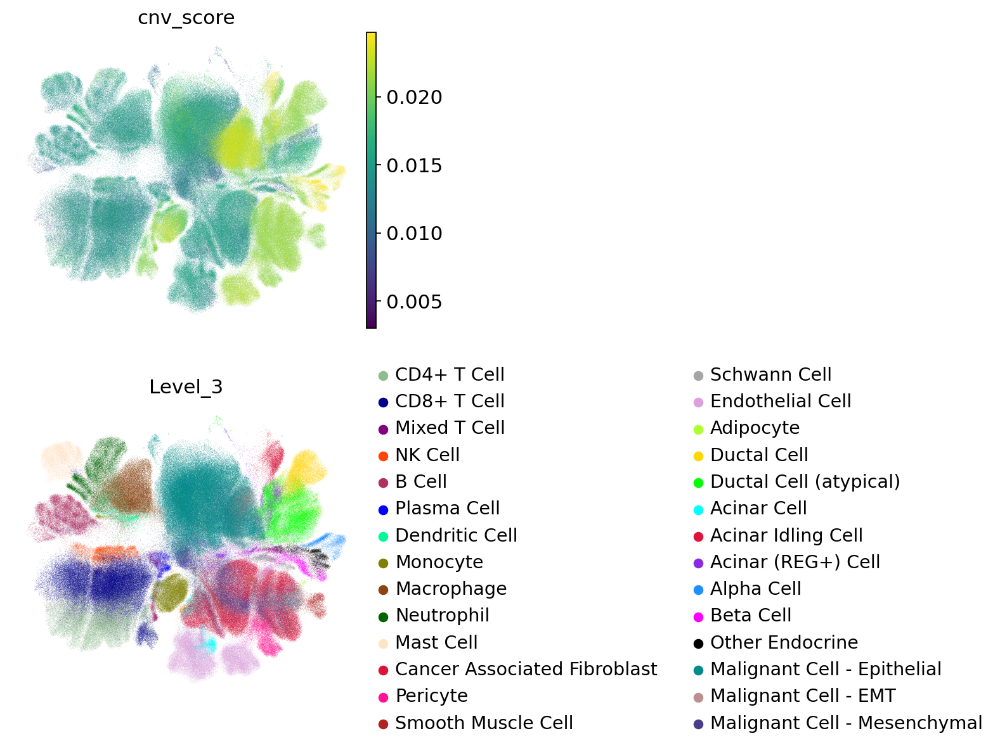

In [54]:
sc.pl.umap(adata_core, color=['cnv_score', 'Level_3'], ncols=1, frameon=False)

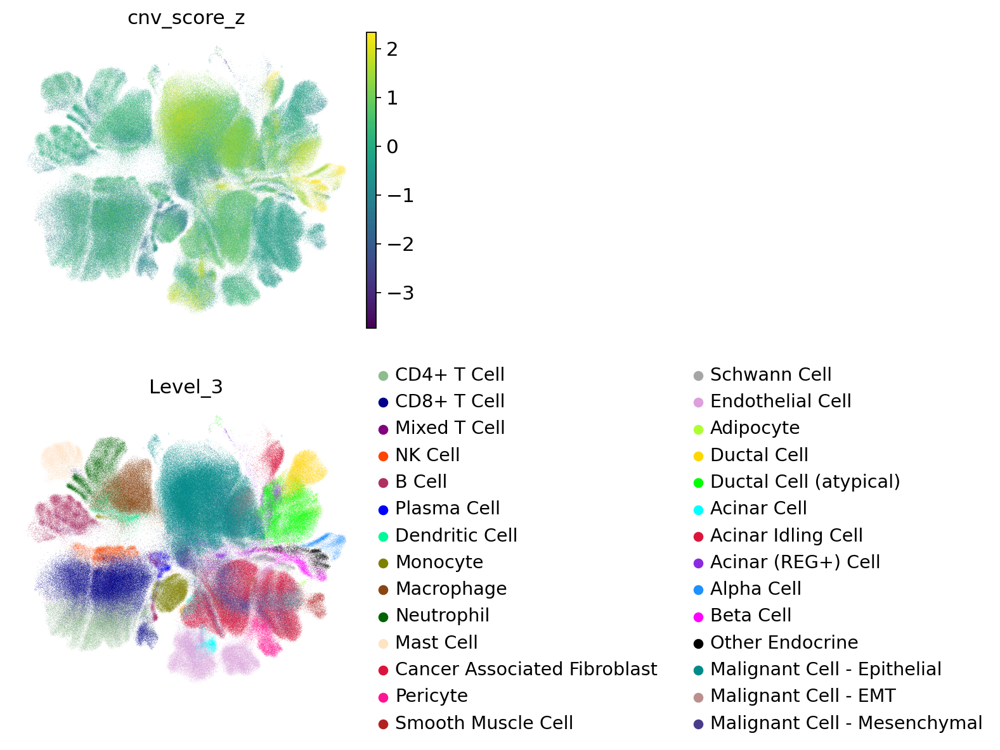

In [55]:
sc.pl.umap(adata_core, color=['cnv_score_z', 'Level_3'], ncols=1, frameon=False)

In [60]:
import pandas as pd
pd.set_option('display.max_rows', None)
adata_core.obs.Level_4.value_counts().sort_index()

Level_4
Acinar (REG+) Cell                           11545
Acinar Cell                                   4342
Acinar Idling Cell                            7407
Adipocyte                                     1459
Alpha Cell                                    4730
B Cell - Activated                           13331
B Cell - Germinal Center                      1121
B Cell - Memory                               4656
B Cell - Naive                                3246
B-reg                                         3920
Beta Cell                                     7035
CD4+ Memory T Cell                            8679
CD4+ Naive T Cell                             4764
CD4+ Th1 Cell                                 4503
CD4+ Th17 Cell                                9406
CD4+ Th2 Cell                                 2705
CD4+ Th22 Cell                                1839
CD8+ Effector T Cell                         22089
CD8+ Exhausted T Cell                        15177
CD8+ Memory T Cell     

In [62]:
# Level_3 palette dictionary
level_3_palette = {
    "Macrophage":                   "#8b4513",
    "Acinar (REG+) Cell":           "#8a2be2",
    "Malignant Cell - Mesenchymal": "#483d8b",
    "B Cell":                       "#b03060",
    "Cancer Associated Fibroblast": "#dc143c",
    "Malignant Cell - Epithelial":  "#008b8b",
    "Monocyte":                     "#808000",
    "Epsilon Cell":                 "#ff8c00",
    "CD4+ T Cell":                  "#8fbc8f",
    "Ductal Cell":                  "#ffd700",
    "Ductal Cell (atypical)":       "#00ff00",
    "Fibroblast":                   "#dc143c",
    "NK Cell":                      "#ff4500",
    "Mixed T Cell":                 "#800080",
    "Gamma Cell":                   "#add8e6",
    "CD8+ T Cell":                  "#00008b",
    "Neutrophil":                   "#006400",
    "Malignant Cell - EMT":         "#bc8f8f",
    "Endothelial Cell":             "#dda0dd",
    "Alpha Cell":                   "#1e90ff",
    "ADM Cell":                     "#00ff00",
    "Dendritic Cell":               "#00fa9a",
    "Beta Cell":                    "#ff00ff",
    "Acinar Idling Cell":           "#dc143c",
    "Delta Cell":                   "#00bfff",
    "Acinar Cell":                  "#00ffff",
    "Plasma Cell":                  "#0000ff",
    "Adipocyte":                    "#adff2f",
    "Mast Cell":                    "#ffe4c4",
    "Other Endocrine":              "#000000",
    "Pericyte":                     "#ff1493",
    "Schwann Cell":                 "#a5a5a5",
    "Smooth Muscle Cell":           "#b22222",
}

# Level_4 palette dictionary
level_4_palette = {
    'Acinar (REG+) Cell': '#a6cee3',
    'Acinar Cell': '#b2df8a',
    'Acinar Idling Cell': '#fdbf6f',
    'ADM Cell': '#cab2d6',
    'Adipocyte': '#ffff99',
    'Alpha Cell': '#b15928',
    'apCAF': '#1f78b4',
    'B Cell - Activated': '#1f78b4',
    'B Cell - Germinal Center': '#33a02c',
    'B Cell - Memory': '#e31a1c',
    'B Cell - Naive': '#6a3d9a',
    'B-reg': '#b15928',
    'Beta Cell': '#1f78b4',
    'CD4+ Memory T Cell': '#a6cee3',
    'CD4+ Naive T Cell': '#b2df8a',
    'CD4+ Th1 Cell': '#fb9a99',
    'CD4+ Th17 Cell': '#e31a1c',
    'CD4+ Th2 Cell': '#cab2d6',
    'CD4+ Th22 Cell': '#1f78b4',
    'CD8+ Effector T Cell': '#a6cee3',
    'CD8+ Memory T Cell': '#b2df8a',
    'CD8+ Naive T Cell': '#fb9a99',
    'CD8+ Terminal Effector T Cell': '#cab2d6',
    'CD8+ Tissue-Resident Memory T Cell': '#b15928',
    'CD8+ Exhausted T Cell': '#33a02c',
    'Dendritic Cell - Activated': '#e377c2',
    'Dendritic Cell - cDC1': '#1f78b4',
    'Dendritic Cell - cDC2': '#e31a1c',
    'Dendritic Cell - pDC': '#6a3d9a',
    'Delta Cell': '#bcbd22',
    'Double Positive CD4+CD8+ T Cell': '#e31a1c',
    'Ductal Cell': '#17becf',
    'Ductal Cell (atypical)': '#9edae5',
    'Epsilon Cell': '#393b79',
    'Fibroblast': '#5254a3',
    'Gamma Cell': '#6b6ecf',
    'γδ T Cell (Vδ1)': '#6a3d9a',
    'iCAF': '#9c9ede',
    'Lymphatic Endothelial Cell': '#637939',
    'Macrophage - angiogenic TAM': '#1f78b4',
    'Macrophage - antigen processing TAM': '#ff7f00',
    'Macrophage - CD3+ TAM': '#e31a1c',
    'Macrophage - C1Q+ TAM': '#6a3d9a',
    'Macrophage - lipid processing TAM': '#b15928',
    'Malignant Cell - Pit Like': "#a6cee3",
    'Malignant Cell - Acinar-like': "#b2df8a",
    'Malignant Cell - Epithelial': "#fb9a99",
    'Malignant Cell - Hypoxia': "#fdbf6f",
    'Malignant Cell - EMT': "#cab2d6",
    'Malignant Cell - Highly Proliferative': "#e31a1c",
    'Malignant Cell - Mesenchymal': "#fed683",
    'Malignant Cell - Highly Invasive': "#6a3d9a",
    'Malignant Cell - Senescence': "#1f78b4",
    'Malignant Cell - Apoptotic': "#b15928",
    'Mast Cell': '#393b79',
    'Monocyte': '#6b6ecf',
    'myCAF': '#9c9ede',
    'Neutrophil - N0': '#1f78b4',
    'Neutrophil - N1': '#33a02c',
    'Neutrophil - N2': '#b15928',
    'NK Cell': '#cedb9c',
    'Other Endocrine': '#8c6d31',
    'Pericyte': '#bd9e39',
    'Plasma Cell': '#e7ba52',
    'Plasmablast': '#e7969c',
    'Schwann Cell': '#843c39',
    'Smooth Muscle Cell': '#ad494a',
    'T-reg': '#b15928',
    'Tumor-Associated Endothelial Cell': '#7b4173',
    'Vascular Endothelial Cell': '#a55194',
}

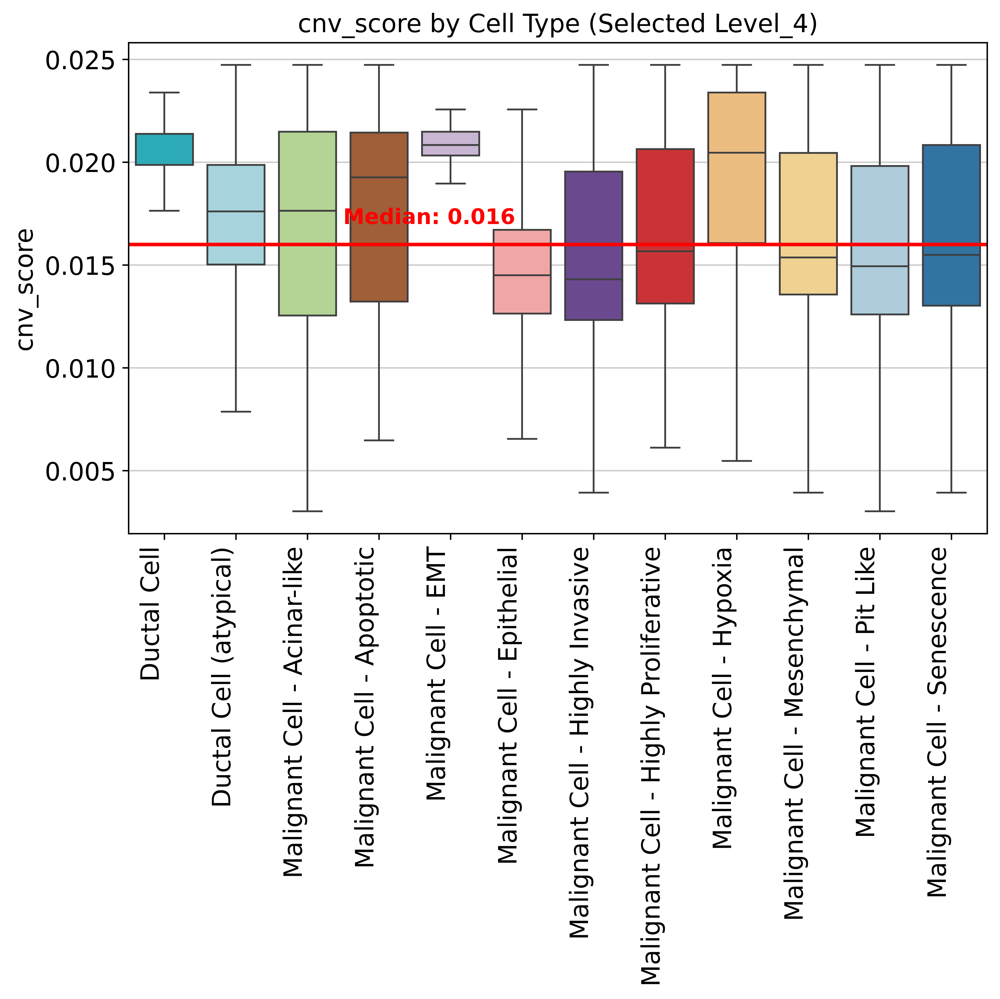

In [65]:
fig, ax = plt.subplots(figsize=(8, 8), dpi=300)

# Inverted order: Ductal > Atypical > Malignants
cell_types = [
    "Ductal Cell",
    "Ductal Cell (atypical)",
    "Malignant Cell - Acinar-like",
    "Malignant Cell - Apoptotic",
    "Malignant Cell - EMT",
    "Malignant Cell - Epithelial",
    "Malignant Cell - Highly Invasive",
    "Malignant Cell - Highly Proliferative",
    "Malignant Cell - Hypoxia",
    "Malignant Cell - Mesenchymal",
    "Malignant Cell - Pit Like",
    "Malignant Cell - Senescence"
]

filtered_obs = adata_core.obs[adata_core.obs['Level_4'].isin(cell_types)].copy()
filtered_obs['Level_4'] = filtered_obs['Level_4'].astype(str)

# Build palette from the Level_4 dict above, for just these cell types:
level4_palette_selected = {ct: level_4_palette[ct] for ct in cell_types if ct in level_4_palette}

# Remove outliers by using the 'showfliers=False' argument
sns.boxplot(
    x='Level_4',
    y='cnv_score',
    data=filtered_obs,
    order=cell_types,     # enforce explicit/inverted order
    palette=level4_palette_selected,
    ax=ax,
    showfliers=False
)

ax.set_ylabel("cnv_score")
ax.set_xlabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha='right')

# Calculate and plot the median
median_cnv = filtered_obs["cnv_score"].median()
ax.axhline(median_cnv, color='red', linestyle='-', linewidth=2)
ax.text(
    x=2.5,  # Centered in the group
    y=median_cnv + 0.001,  # Slightly above the line
    s=f"Median: {median_cnv:.3f}",
    color='red',
    fontsize=12,
    fontweight='bold'
)

ax.set_title("cnv_score by Cell Type (Selected Level_4)")
fig.tight_layout()
fig.savefig("malignant_states_cnv_score_selected_Level4_boxplot.png", dpi=300)
plt.show()

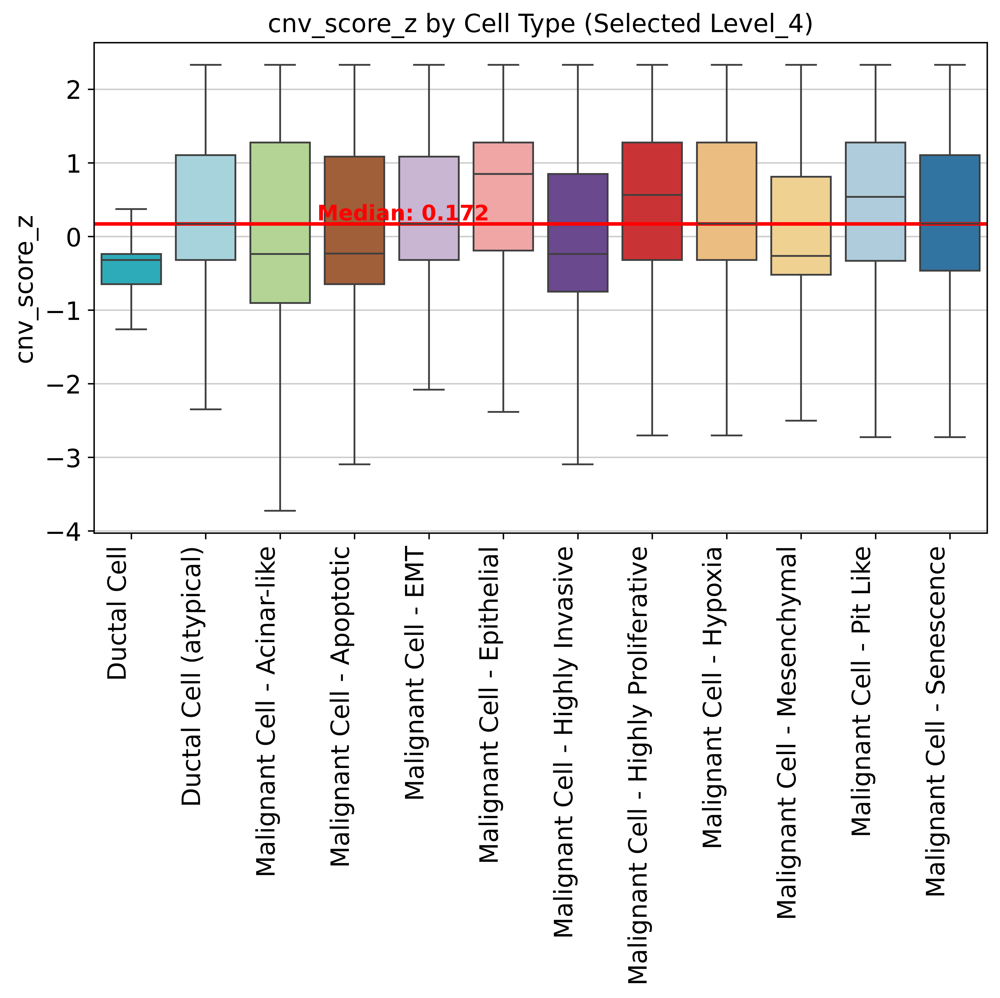

In [66]:
fig, ax = plt.subplots(figsize=(8, 8), dpi=300)

# Inverted order: Ductal > Atypical > Malignants
cell_types = [
    "Ductal Cell",
    "Ductal Cell (atypical)",
    "Malignant Cell - Acinar-like",
    "Malignant Cell - Apoptotic",
    "Malignant Cell - EMT",
    "Malignant Cell - Epithelial",
    "Malignant Cell - Highly Invasive",
    "Malignant Cell - Highly Proliferative",
    "Malignant Cell - Hypoxia",
    "Malignant Cell - Mesenchymal",
    "Malignant Cell - Pit Like",
    "Malignant Cell - Senescence"
]

filtered_obs = adata_core.obs[adata_core.obs['Level_4'].isin(cell_types)].copy()
filtered_obs['Level_4'] = filtered_obs['Level_4'].astype(str)

# Build palette from the Level_4 dict above, for just these cell types:
level4_palette_selected = {ct: level_4_palette[ct] for ct in cell_types if ct in level_4_palette}

# Remove outliers by using the 'showfliers=False' argument
sns.boxplot(
    x='Level_4',
    y='cnv_score_z',
    data=filtered_obs,
    order=cell_types,     # enforce explicit/inverted order
    palette=level4_palette_selected,
    ax=ax,
    showfliers=False
)

ax.set_ylabel("cnv_score_z")
ax.set_xlabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha='right')

# Calculate and plot the median
median_cnv = filtered_obs["cnv_score_z"].median()
ax.axhline(median_cnv, color='red', linestyle='-', linewidth=2)
ax.text(
    x=2.5,  # Centered in the group
    y=median_cnv + 0.05,  # Slightly above the line, increased for z-scored data
    s=f"Median: {median_cnv:.3f}",
    color='red',
    fontsize=12,
    fontweight='bold'
)

ax.set_title("cnv_score_z by Cell Type (Selected Level_4)")
fig.tight_layout()
fig.savefig("malignant_states_cnv_score_z_selected_Level4_boxplot.png", dpi=300)
plt.show()

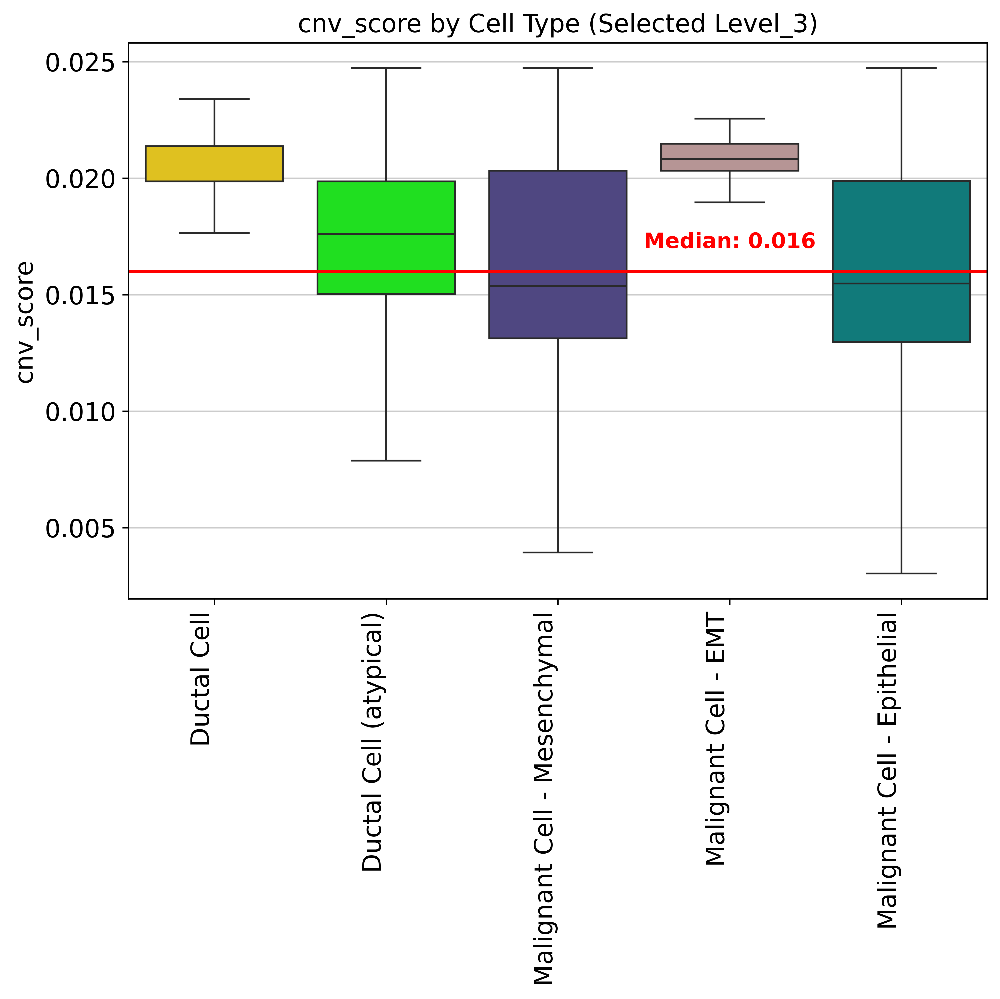

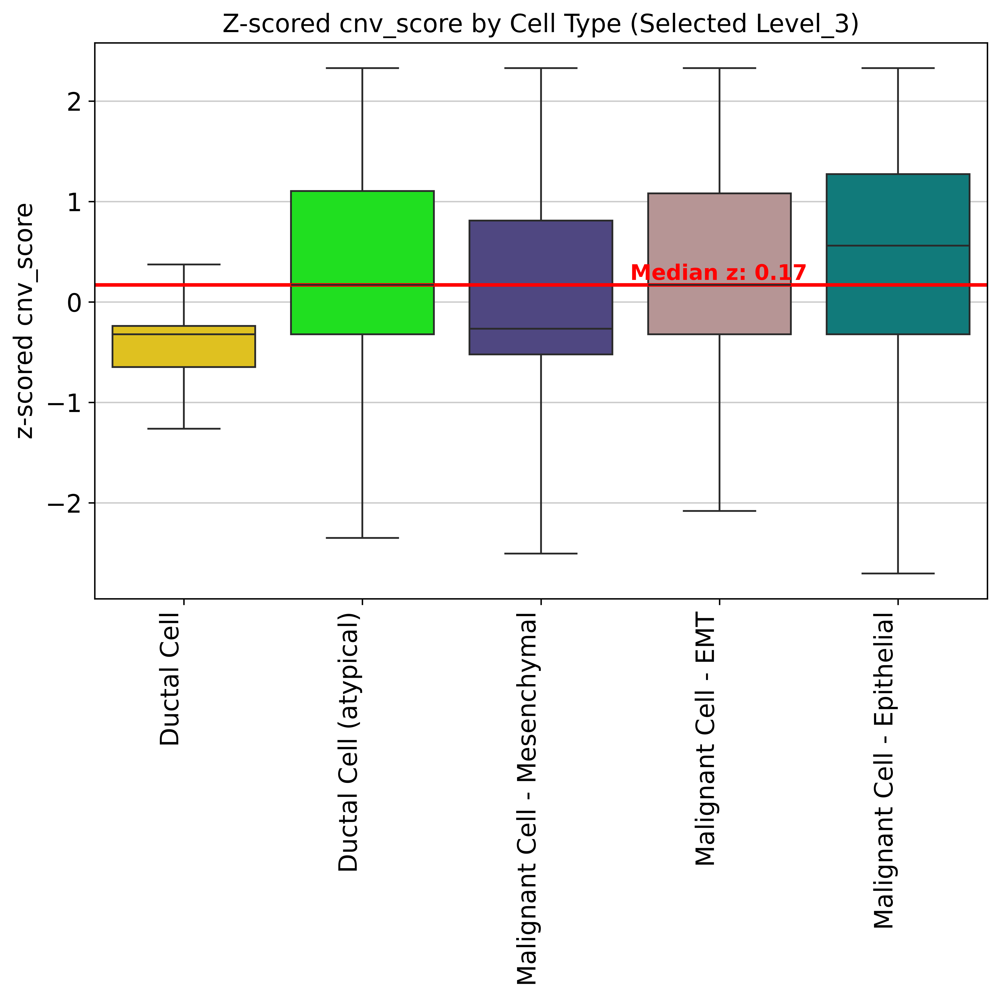

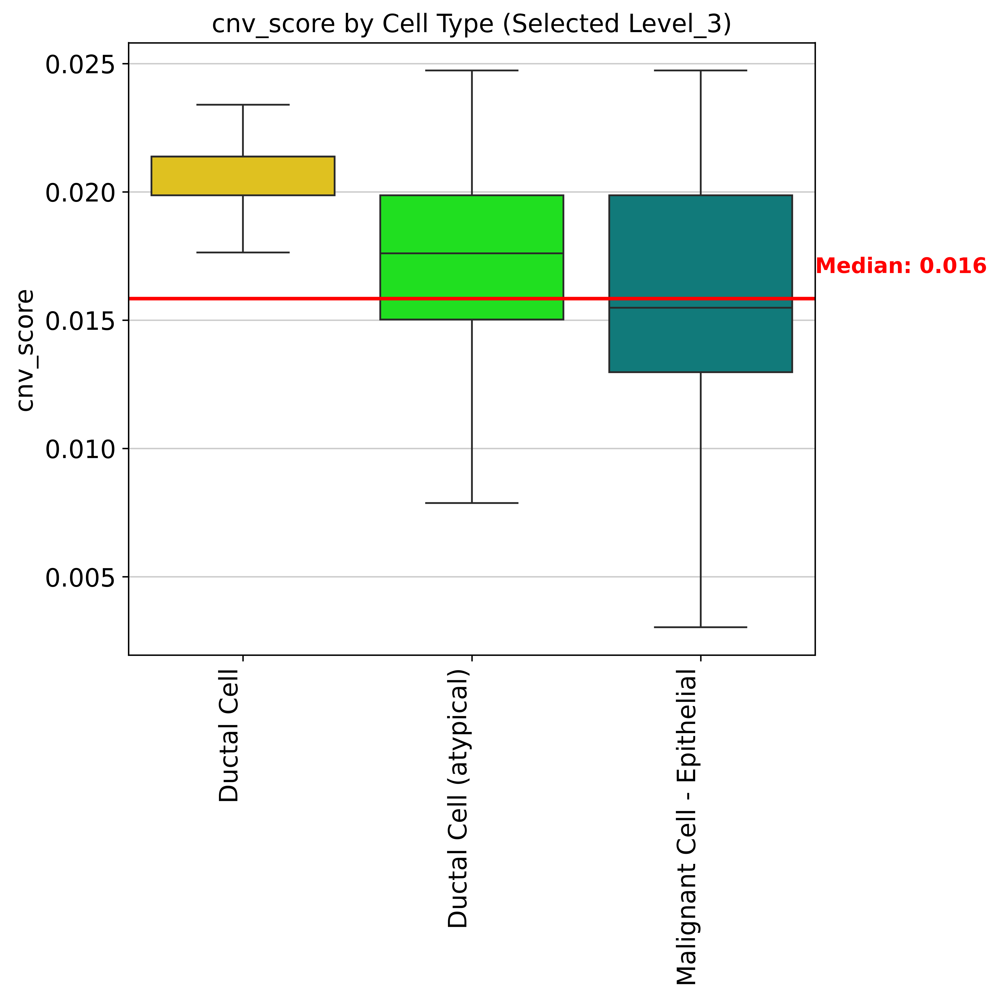

In [71]:

# 1. Boxplot: Level_3 (full malignant/EMT/mesenchymal/ductal) using custom palette
fig, ax = plt.subplots(figsize=(8, 8), dpi=300)

cell_types = [
    "Ductal Cell", "Ductal Cell (atypical)",
    "Malignant Cell - Mesenchymal", "Malignant Cell - EMT", "Malignant Cell - Epithelial"
]

filtered_obs = adata_core.obs[adata_core.obs['Level_3'].isin(cell_types)].copy()
filtered_obs['Level_3'] = filtered_obs['Level_3'].astype(str)

# Build palette from level_3_palette
level3_palette_selected = {ct: level_3_palette[ct] for ct in cell_types if ct in level_3_palette}

sns.boxplot(
    x='Level_3',
    y='cnv_score',
    data=filtered_obs,
    order=cell_types,
    palette=level3_palette_selected,
    ax=ax,
    showfliers=False
)

ax.set_ylabel("cnv_score")
ax.set_xlabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha='right')

median_cnv = filtered_obs["cnv_score"].median()
ax.axhline(median_cnv, color='red', linestyle='-', linewidth=2)
ax.text(
    x=2.5,
    y=median_cnv + 0.001,
    s=f"Median: {median_cnv:.3f}",
    color='red',
    fontsize=12,
    fontweight='bold'
)

ax.set_title("cnv_score by Cell Type (Selected Level_3)")
fig.tight_layout()
fig.savefig("ductal_cnv_score_selected_Level3_boxplot.png", dpi=300)
plt.show()

# 2. Boxplot: Level_3 z-scored CNV, using custom palette
fig, ax = plt.subplots(figsize=(8, 8), dpi=300)

# cell_types list is the same as above
filtered_obs = adata_core.obs[adata_core.obs['Level_3'].isin(cell_types)].copy()
filtered_obs['Level_3'] = filtered_obs['Level_3'].astype(str)

sns.boxplot(
    x='Level_3',
    y='cnv_score_z',
    data=filtered_obs,
    order=cell_types,
    palette=level3_palette_selected,
    ax=ax,
    showfliers=False
)

ax.set_ylabel("z-scored cnv_score")
ax.set_xlabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha='right')

median_cnv_z = filtered_obs["cnv_score_z"].median()
ax.axhline(median_cnv_z, color='red', linestyle='-', linewidth=2)
ax.text(
    x=2.5,
    y=median_cnv_z + 0.05,
    s=f"Median z: {median_cnv_z:.2f}",
    color='red',
    fontsize=12,
    fontweight='bold'
)

ax.set_title("Z-scored cnv_score by Cell Type (Selected Level_3)")
fig.tight_layout()
fig.savefig("ductal_z_cnv_score_selected_Level3_boxplot.png", dpi=300)
plt.show()

# 3. Boxplot: Only Ductal, Atypical, Epithelial - custom palette
fig, ax = plt.subplots(figsize=(8, 8), dpi=300)

cell_types_epi = [
    "Ductal Cell", "Ductal Cell (atypical)", "Malignant Cell - Epithelial"
]

filtered_obs = adata_core.obs[adata_core.obs['Level_3'].isin(cell_types_epi)].copy()
filtered_obs['Level_3'] = filtered_obs['Level_3'].astype(str)

level3_palette_selected_epi = {ct: level_3_palette[ct] for ct in cell_types_epi if ct in level_3_palette}

sns.boxplot(
    x='Level_3',
    y='cnv_score',
    data=filtered_obs,
    order=cell_types_epi,
    palette=level3_palette_selected_epi,
    ax=ax,
    showfliers=False
)

ax.set_ylabel("cnv_score")
ax.set_xlabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha='right')

median_cnv = filtered_obs["cnv_score"].median()
ax.axhline(median_cnv, color='red', linestyle='-', linewidth=2)
ax.text(
    x=2.5,
    y=median_cnv + 0.001,
    s=f"Median: {median_cnv:.3f}",
    color='red',
    fontsize=12,
    fontweight='bold'
)

ax.set_title("cnv_score by Cell Type (Selected Level_3)")
fig.tight_layout()
fig.savefig("epi_ductal_cnv_score_selected_Level3_boxplot.png", dpi=300)
plt.show()

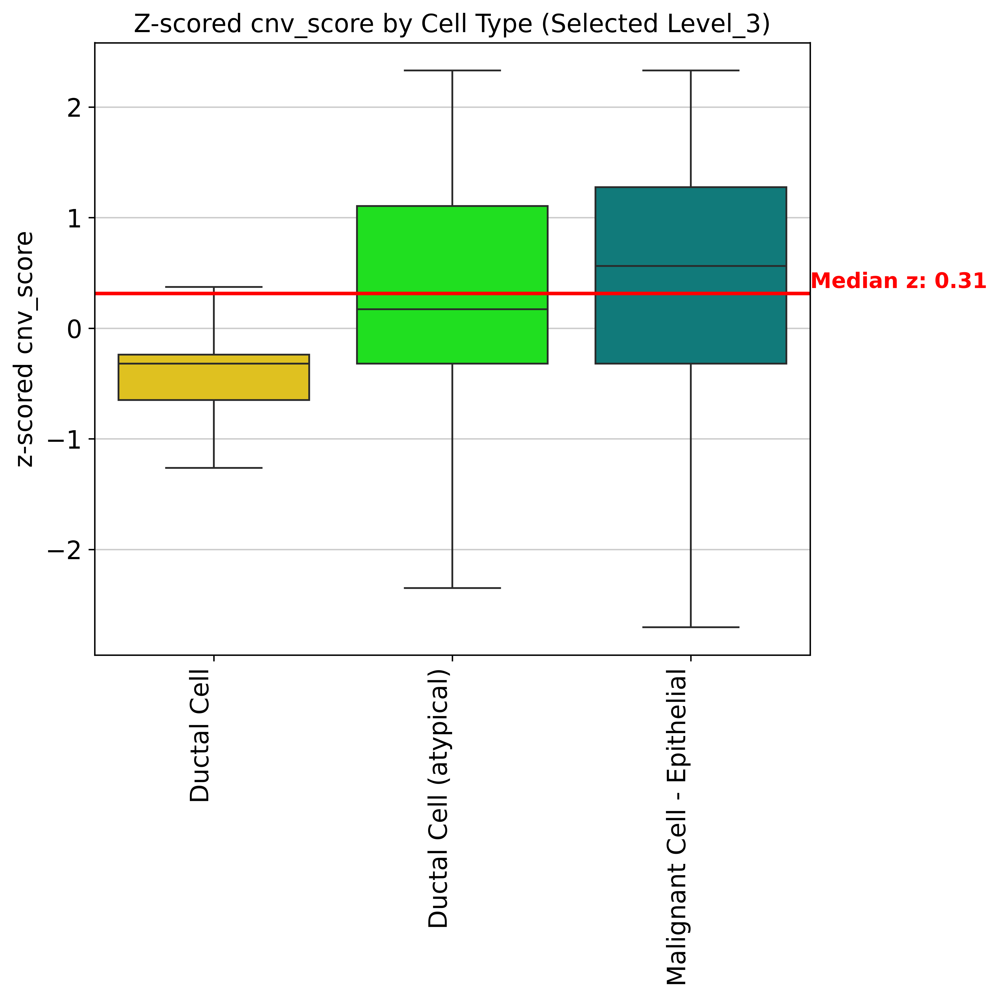

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, ax = plt.subplots(figsize=(8, 8), dpi=300)

# Inverted order: Ductal > Atypical > Malignants (Epithelial, EMT, Mesenchymal)
cell_types = [
    "Ductal Cell", "Ductal Cell (atypical)", "Malignant Cell - Epithelial"
]

filtered_obs = adata_core.obs[adata_core.obs['Level_3'].isin(cell_types)].copy()
filtered_obs['Level_3'] = filtered_obs['Level_3'].astype(str)

level3_palette_selected_epi = {ct: level_3_palette[ct] for ct in cell_types if ct in level_3_palette}

# Remove outliers by using the 'showfliers=False' argument
sns.boxplot(
    x='Level_3',
    y='cnv_score_z',
    data=filtered_obs,
    order=cell_types,     # enforce explicit/inverted order
    palette=level3_palette_selected_epi,
    ax=ax,
    showfliers=False
)

ax.set_ylabel("z-scored cnv_score")
ax.set_xlabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha='right')

# Calculate and plot the median of z-scored cnv_scores
median_cnv_z = filtered_obs["cnv_score_z"].median()
ax.axhline(median_cnv_z, color='red', linestyle='-', linewidth=2)
ax.text(
    x=2.5,  # Centered in the group
    y=median_cnv_z + 0.05,  # Slightly above the line (smaller for z-scale)
    s=f"Median z: {median_cnv_z:.2f}",
    color='red',
    fontsize=12,
    fontweight='bold'
)

ax.set_title("Z-scored cnv_score by Cell Type (Selected Level_3)")
fig.tight_layout()
fig.savefig("epi_ductal_z_cnv_score_selected_Level3_boxplot.png", dpi=300)
plt.show()

In [72]:
pwd

'/workspace/PDAC_Work_Dir/PDAC_Final/PDAC_Revisions'